## `SP-Buy — Fraud Detection Model Training`

1. **XGBoost** — Baseline, staged improvements, decision threshold and final test.
2. **Logistic Regression** — Baseline, targeted improvements, decision threshold and final test.

To rerun the notebook, update `DATA_PATH` in the XGBoost **Load and Validate the Cleaned Dataset** cell to point to your `model_data.csv`. Both models use the chronological partitions created in that section. Run the cells from the top in one Python kernel.

## `SP-Buy — XGBoost Model Training and Fraud Detection`

### Project Background

SP-Buy needs to identify suspicious orders for review. This notebook trains an `XGBoost` classifier to rank orders by their fraud scores and tests how different decision thresholds affect the number of orders flagged.

- **Model input** — Eight order-level features from the cleaned `model_data.csv`.
- **Prediction target** — `is_fraud`, where `1` indicates fraud and `0` indicates a legitimate order.
- **Model selection** — Compare configurations by validation **average precision (AP)**, which measures how well fraud is ranked across thresholds.
- **Threshold selection** — Maximise validation fraud **F1**, then apply the chosen cutoff to later orders in the test period.


### 1️⃣ Imports and Data Preparation for XGBoost Model

- Use `pandas` and `NumPy` to prepare the data, `scikit-learn` for preprocessing and metrics, and `XGBoost` for classification.
- Set `RANDOM_STATE = 42` for the model and use `0.5` as the shared cutoff for the first comparison.

In [1]:
from pathlib import Path
from itertools import product

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display

from sklearn.linear_model import LogisticRegression
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.model_selection import train_test_split

from sklearn.metrics import (
    average_precision_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    precision_recall_curve,
    accuracy_score
)

from xgboost import XGBClassifier
from xgboost.callback import EarlyStopping


RANDOM_STATE = 42
BASELINE_THRESHOLD = 0.5

#### `Load and Validate the Cleaned Dataset`

- Load **949,872 orders** from `model_data.csv` in the saved run.
- Verify the required columns, valid order dates, unique `(country_code, order_id)` keys and binary fraud labels.
- Treat missing categorical values as `Unknown`. Handle missing numeric values during preprocessing.

| Feature group | Fields |
|---|---|
| **Numeric** | `order_value`, `num_items_ordered`, `days_since_first_order`, `value_per_item` |
| **Categorical** | `country_code`, `collect_type`, `payment_method`, `order_weekday` |

In [2]:
DATA_PATH = Path(r"C:\Users\jxcye\Documents\SP-Buy-Project\model_data.csv")  # Update the path if needed.

TARGET = "is_fraud"
DATE_COLUMN = "order_date"
ORDER_KEYS = ["country_code", "order_id"]

NUMERIC_FEATURES = [
    "order_value",
    "num_items_ordered",
    "days_since_first_order",
    "value_per_item"
]

CATEGORICAL_FEATURES = [
    "country_code",
    "collect_type",
    "payment_method",
    "order_weekday"
]

FEATURES = NUMERIC_FEATURES + CATEGORICAL_FEATURES

df = pd.read_csv(
    DATA_PATH,
    dtype={
        "country_code": "string",
        "order_id": "string",
        "customer_id": "string"
    }
)

required_columns = list(dict.fromkeys(
    ORDER_KEYS + [DATE_COLUMN, TARGET] + FEATURES
))

missing_columns = sorted(set(required_columns) - set(df.columns))

if missing_columns:
    raise ValueError(f"Missing required columns: {missing_columns}")

df[DATE_COLUMN] = pd.to_datetime(
    df[DATE_COLUMN],
    errors="raise"
).dt.normalize()

if df[DATE_COLUMN].isna().any():
    raise ValueError("Missing order dates.")

for column in ORDER_KEYS:
    if (
        df[column].isna().any()
        or df[column].str.strip().eq("").any()
    ):
        raise ValueError(f"Missing or blank values in {column}.")

if df.duplicated(ORDER_KEYS).any():
    raise ValueError("Duplicate composite order keys found.")

if df[TARGET].isna().any() or not df[TARGET].isin([0, 1]).all():
    raise ValueError("is_fraud must contain only 0 and 1.")

df[TARGET] = df[TARGET].astype(int)

for column in NUMERIC_FEATURES:
    df[column] = pd.to_numeric(df[column], errors="raise")

if np.isinf(df[NUMERIC_FEATURES].to_numpy(dtype=float)).any():
    raise ValueError("Infinite numeric values found.")

# Standardise categorical missing values for sklearn preprocessing.
for column in CATEGORICAL_FEATURES:
    df[column] = (
        df[column]
        .astype("string")
        .fillna("Unknown")
        .astype(str)
    )

print("Dataset shape:", df.shape)
display(df.head())

display(
    df[FEATURES + [TARGET]]
    .isna()
    .sum()
    .rename("Missing values")
    .to_frame()
)

Dataset shape: (949872, 12)


,country_code,order_id,customer_id,order_date,collect_type,payment_method,order_value,num_items_ordered,is_fraud,days_since_first_order,value_per_item,order_weekday
0,TH,b9ce4cdead,4a2deee064,2022-12-31,delivery,payment on delivery,13.877272,1.0,0,1250.0,13.877272,Saturday
1,MY,eae640c3dd,0e39f85e6d,2023-03-27,delivery,boost wallet,2.512021,1.0,0,8.0,2.512021,Monday
2,PH,6b5eff4d8f,b88034bb7a,2022-11-16,delivery,payment on delivery,4.309368,3.0,0,138.0,1.436456,Wednesday
3,MY,31928238a7,b24be37d24,2023-01-02,delivery,credit card,8.090340,1.0,0,939.0,8.090340,Monday
4,MY,4adec8e335,996287540f,2023-04-02,delivery,Unknown,8.934508,2.0,0,383.0,4.467254,Sunday


,Missing values
order_value,0
num_items_ordered,1
days_since_first_order,876
value_per_item,1
country_code,0
collect_type,0
payment_method,0
order_weekday,0
is_fraud,0


#### `Chronological Data Split`

- Sort orders by date and choose cutoff dates near the **70%** and **85%** positions.
- Keep all orders from the same day together. This gives an approximately **70/15/15** split and mirrors how the model would be applied to later orders.
- Use the training set to fit the model, validation to guide tuning, and the newest period for final testing.

In [3]:
df = df.sort_values(
    [DATE_COLUMN, "country_code", "order_id"],
    kind="stable"
).reset_index(drop=True)

n_rows = len(df)

validation_start = df.iloc[int(n_rows * 0.70)][DATE_COLUMN]
test_start = df.iloc[int(n_rows * 0.85)][DATE_COLUMN]

if validation_start >= test_start:
    raise ValueError("Not enough distinct dates for this split.")

train_df = df.loc[
    df[DATE_COLUMN] < validation_start
].copy()

val_df = df.loc[
    (df[DATE_COLUMN] >= validation_start)
    & (df[DATE_COLUMN] < test_start)
].copy()

test_df = df.loc[
    df[DATE_COLUMN] >= test_start
].copy()

partitions = {
    "Train": train_df,
    "Validation": val_df,
    "Test": test_df
}

for name, partition in partitions.items():
    if partition.empty:
        raise ValueError(f"{name} partition is empty.")

    if partition[TARGET].nunique() != 2:
        raise ValueError(f"{name} must contain both classes.")

assert len(train_df) + len(val_df) + len(test_df) == len(df)
assert train_df[DATE_COLUMN].max() < val_df[DATE_COLUMN].min()
assert val_df[DATE_COLUMN].max() < test_df[DATE_COLUMN].min()

split_summary = pd.DataFrame([
    {
        "Partition": name,
        "Orders": len(partition),
        "Dataset percentage": 100 * len(partition) / len(df),
        "Start date": partition[DATE_COLUMN].min(),
        "End date": partition[DATE_COLUMN].max(),
        "Fraud orders": int(partition[TARGET].sum()),
        "Fraud percentage": 100 * partition[TARGET].mean()
    }
    for name, partition in partitions.items()
])

display(split_summary.round(4))

X_train = train_df[FEATURES].copy()
y_train = train_df[TARGET].copy()

X_val = val_df[FEATURES].copy()
y_val = val_df[TARGET].copy()

X_test = test_df[FEATURES].copy()
y_test = test_df[TARGET].copy()

C:\Users\jxcye\AppData\Local\Temp\ipykernel_12544\2547932779.py:57: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(split_summary.round(4))


,Partition,Orders,Dataset percentage,Start date,End date,Fraud orders,Fraud percentage
0,Train,660772,69.5643,2022-11-12,2023-03-14,66847,10.1165
1,Validation,144978,15.2629,2023-03-15,2023-04-13,19740,13.6159
2,Test,144122,15.1728,2023-04-14,2023-05-11,17835,12.3749


#### Data Split Summary

| Partition | Orders | Date range | Fraud rate |
|---|---:|---|---:|
| Training | 660,772 | 12 Nov 2022 – 14 Mar 2023 | 10.12% |
| Validation | 144,978 | 15 Mar – 13 Apr 2023 | 13.62% |
| Test | 144,122 | 14 Apr – 11 May 2023 | 12.37% |

### 2️⃣ Build and Evaluate the Baseline XGBoost Model

XGBoost builds decision trees in sequence. Each new tree adjusts the ensemble's predictions by learning from errors made in earlier rounds. The baseline provides a reference for measuring the effect of tuning.

#### `Fit Preprocessing on Training Data`

- Fill missing numeric values with the training-set median.
- One-hot encode categorical features and ignore unseen categories when transforming later data.
- Reuse the fitted preprocessor for validation and test. The eight input fields produce **36 encoded features** in the saved run.
- Calculate the training ratio of legitimate to fraudulent orders (**8.8848**) for the fraud-weighting experiment.

In [4]:
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_pipeline = Pipeline([
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False,
        dtype=np.float32
    ))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, NUMERIC_FEATURES),
    ("categorical", categorical_pipeline, CATEGORICAL_FEATURES)
])

X_train_encoded = preprocessor.fit_transform(X_train).astype(
    np.float32
)

X_val_encoded = preprocessor.transform(X_val).astype(
    np.float32
)

feature_names = preprocessor.get_feature_names_out()

print("Encoded training shape:", X_train_encoded.shape)
print("Encoded validation shape:", X_val_encoded.shape)

training_positives = int(y_train.sum())
training_negatives = int(len(y_train) - training_positives)

fraud_weight_ratio = training_negatives / training_positives

print(f"Training negatives / positives: {fraud_weight_ratio:.4f}")

Encoded training shape: (660772, 36)
Encoded validation shape: (144978, 36)
Training negatives / positives: 8.8848


#### `Define Shared Evaluation Metrics`

| Metric | What it tells us |
|---|---|
| **Average precision (AP)** | How well the model ranks fraudulent orders across decision thresholds |
| **Fraud precision** | Of the orders flagged, how many were fraudulent |
| **Fraud recall** | Of the fraudulent orders, how many were flagged |
| **Fraud F1** | The harmonic mean of fraud precision and recall |
| **Flagged percentage** | The share of all orders sent for review |
| **Confusion matrix** | Correct predictions, false alerts and missed fraud |

In [5]:
def evaluate_fraud_threshold(
    y_true, scores, threshold, run_name
):
    scores = np.asarray(scores, dtype=float)
    predictions = (scores >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_true, predictions, labels=[0, 1]
    ).ravel()

    return {
        "Run": run_name,
        "Threshold": float(threshold),

        "Average precision": average_precision_score(
            y_true, scores
        ),
        "Fraud precision": precision_score(
            y_true, predictions,
            pos_label=1, zero_division=0
        ),
        "Fraud recall": recall_score(
            y_true, predictions,
            pos_label=1, zero_division=0
        ),
        "Fraud F1": f1_score(
            y_true, predictions,
            pos_label=1, zero_division=0
        ),

        "Flagged orders": int(predictions.sum()),
        "Flagged percentage": 100 * predictions.mean(),

        "True negatives": int(tn),
        "False positives": int(fp),
        "False negatives": int(fn),
        "True positives": int(tp)
    }


def plot_confusion_matrices(y_true, cases, title):
    """
    cases:
        [(display_name, scores, threshold), ...]
    """
    fig, axes = plt.subplots(
        1, len(cases),
        figsize=(6 * len(cases), 5),
        squeeze=False
    )

    for ax, (name, scores, threshold) in zip(
        axes.ravel(), cases
    ):
        predictions = (
            np.asarray(scores) >= threshold
        ).astype(int)

        ConfusionMatrixDisplay.from_predictions(
            y_true,
            predictions,
            labels=[0, 1],
            display_labels=["Genuine", "Fraud"],
            cmap="Blues",
            values_format="d",
            colorbar=False,
            ax=ax
        )

        ax.set_title(f"{name}\nThreshold = {threshold:.4f}")
        ax.set_xlabel("Predicted class")
        ax.set_ylabel("Actual class")

    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

#### `Baseline Settings and Experiment Setup`

| Setting | Baseline value |
|---|---:|
| Boosting rounds | `100` |
| Maximum tree depth | `6` |
| Learning rate | `0.3` |
| Fraud class weight | `1.0` |
| Row and column sampling | `1.0` each |

- Record the training AP, validation AP and validation results at the shared cutoff of `0.5` for each run.
- Rank model configurations by validation AP. Runs with early stopping monitor XGBoost's validation `aucpr` during training, while the experiment table ranks them using scikit-learn's AP.

In [6]:
BASE_PARAMS = {
    "objective": "binary:logistic",
    "n_estimators": 100,
    "max_depth": 6,
    "learning_rate": 0.3,

    "subsample": 1.0,
    "colsample_bytree": 1.0,
    "scale_pos_weight": 1.0,

    "reg_lambda": 1.0,
    "min_child_weight": 1.0,
    "gamma": 0.0,

    "tree_method": "hist",
    "eval_metric": ["logloss", "aucpr"],
    "random_state": RANDOM_STATE,
    "n_jobs": 4
}

experiment_models = {}
experiment_configs = {}
validation_scores = {}
experiment_rows = []


def fit_experiment(
    run_name,
    stage,
    params,
    use_early_stopping=False
):
    if run_name in experiment_models:
        raise ValueError(
            f"{run_name} already exists. "
            "Restart from the experiment-storage cell to rerun."
        )

    model_params = params.copy()

    if use_early_stopping:
        model_params["callbacks"] = [
            EarlyStopping(
                rounds=50,
                metric_name="aucpr",
                data_name="validation_1",
                maximize=True,
                save_best=True
            )
        ]

    model = XGBClassifier(**model_params)

    model.fit(
        X_train_encoded,
        y_train,
        eval_set=[
            (X_train_encoded, y_train),
            (X_val_encoded, y_val)
        ],
        verbose=False
    )

    train_scores = model.predict_proba(
        X_train_encoded
    )[:, 1]

    val_scores = model.predict_proba(
        X_val_encoded
    )[:, 1]

    row = evaluate_fraud_threshold(
        y_val,
        val_scores,
        BASELINE_THRESHOLD,
        run_name
    )

    train_ap = average_precision_score(
        y_train, train_scores
    )

    row.update({
        "Stage": stage,
        "Train AP": train_ap,
        "AP gap": train_ap - row["Average precision"],
        "Trees retained": model.get_booster().num_boosted_rounds(),
        "Max depth": params["max_depth"],
        "Fraud weight": params["scale_pos_weight"],
        "Learning rate": params["learning_rate"],
        "Subsample": params["subsample"],
        "Column sample": params["colsample_bytree"],
        "Early stopping": use_early_stopping
    })

    experiment_models[run_name] = model
    experiment_configs[run_name] = {
        "params": params.copy(),
        "early_stopping": use_early_stopping
    }
    validation_scores[run_name] = val_scores
    experiment_rows.append(row)

    print(
        f"{run_name}: "
        f"AP={row['Average precision']:.4f}, "
        f"F1@0.5={row['Fraud F1']:.4f}, "
        f"trees={row['Trees retained']}"
    )

    return model


def ranked_results():
    return (
        pd.DataFrame(experiment_rows)
        .sort_values(
            ["Average precision", "Run"],
            ascending=[False, True]
        )
        .reset_index(drop=True)
    )


def best_run_so_far():
    return ranked_results().iloc[0]["Run"]


def show_results():
    columns = [
        "Run", "Stage",
        "Train AP", "Average precision", "AP gap",
        "Fraud precision", "Fraud recall", "Fraud F1",
        "Flagged percentage",
        "False positives", "False negatives",
        "Trees retained"
    ]

    display(ranked_results()[columns].round(4))

#### `Train and Evaluate the Baseline`

Train `XGB_baseline` for **100 rounds**, then score the validation orders and use the confusion matrix to see how many genuine and fraudulent orders were flagged.

In [7]:
BASELINE_RUN = "XGB_baseline"

xgb_baseline = fit_experiment(
    run_name=BASELINE_RUN,
    stage="Baseline",
    params=BASE_PARAMS,
    use_early_stopping=False
)

baseline_results = pd.DataFrame([
    evaluate_fraud_threshold(
        y_val,
        validation_scores[BASELINE_RUN],
        BASELINE_THRESHOLD,
        BASELINE_RUN
    )
])

display(baseline_results.round(4))

XGB_baseline: AP=0.5282, F1@0.5=0.3049, trees=100


,Run,Threshold,Average precision,Fraud precision,Fraud recall,Fraud F1,Flagged orders,Flagged percentage,True negatives,False positives,False negatives,True positives
0,XGB_baseline,0.5,0.5282,0.6727,0.1972,0.3049,5786,3.991,123344,1894,15848,3892


#### `Baseline Confusion Matrix`

Count correctly classified orders, false alerts and missed fraud on validation at the fixed cutoff of **0.5**.

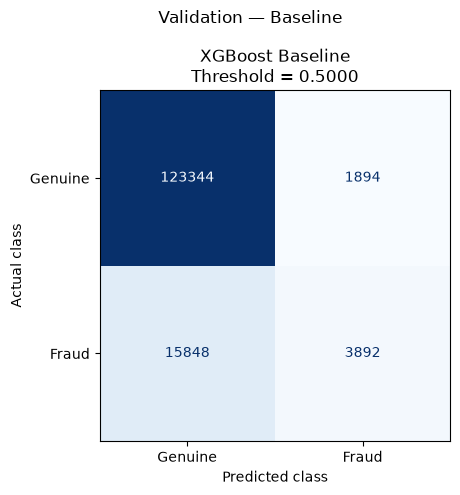

In [8]:
plot_confusion_matrices(
    y_val,
    cases=[
        (
            "XGBoost Baseline",
            validation_scores[BASELINE_RUN],
            BASELINE_THRESHOLD
        )
    ],
    title="Validation — Baseline"
)

#### `Baseline Performance Chart`

The bar chart shows accuracy alongside fraud precision, recall and F1. With fraud making up **13.62%** of validation orders, recall and the confusion matrix help reveal missed fraud that overall accuracy can hide.

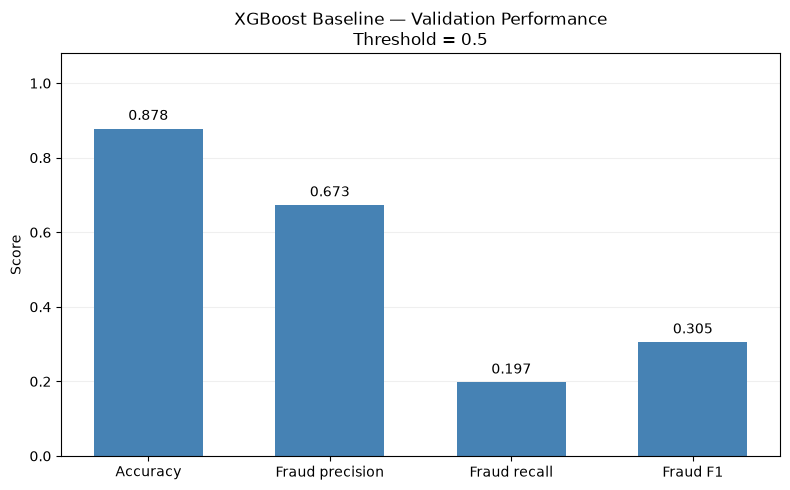

In [9]:
from sklearn.metrics import accuracy_score

baseline_predictions = (
    validation_scores[BASELINE_RUN] >= BASELINE_THRESHOLD
).astype(int)

baseline_row = baseline_results.iloc[0]

metric_labels = [
    "Accuracy", "Fraud precision", "Fraud recall", "Fraud F1"
]

baseline_values = [
    accuracy_score(y_val, baseline_predictions),
    baseline_row["Fraud precision"],
    baseline_row["Fraud recall"],
    baseline_row["Fraud F1"]
]

fig, ax = plt.subplots(figsize=(8, 5))

bars = ax.bar(
    metric_labels,
    baseline_values,
    color="steelblue",
    width=0.6
)

ax.bar_label(bars, fmt="%.3f", padding=4)

ax.set(
    title="XGBoost Baseline — Validation Performance\nThreshold = 0.5",
    ylabel="Score",
    ylim=(0, 1.08)
)

ax.set_yticks(np.arange(0, 1.01, 0.2))
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

#### `Baseline Score Distributions`

Compare the distribution of validation fraud scores within each actual class. The dashed line marks the **0.5** cutoff.

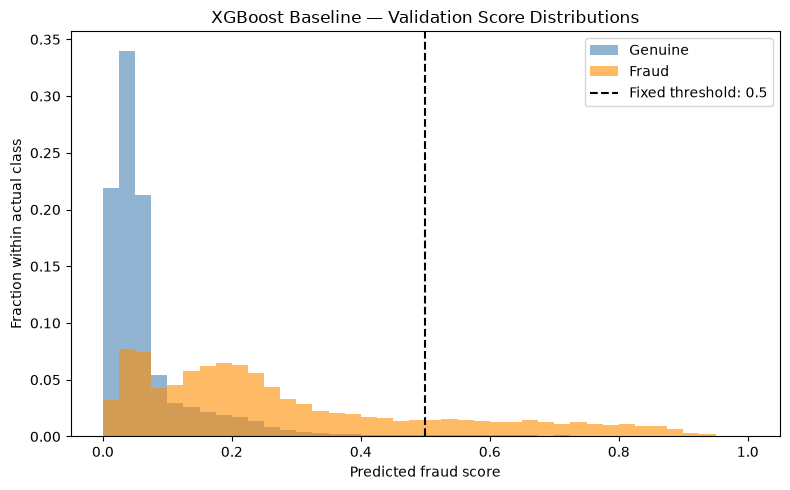

In [10]:
fig, ax = plt.subplots(figsize=(8, 5))
xgb_actual_labels = np.asarray(y_val)

for label, name, color in [(0, "Genuine", "steelblue"), (1, "Fraud", "darkorange")]:
    scores = validation_scores[BASELINE_RUN][xgb_actual_labels == label]
    ax.hist(
        scores,
        bins=np.linspace(0, 1, 41),
        weights=np.full(len(scores), 1 / len(scores)),
        alpha=0.6,
        color=color,
        label=name
    )

ax.axvline(BASELINE_THRESHOLD, color="black", linestyle="--", label="Fixed threshold: 0.5")
ax.set(
    xlabel="Predicted fraud score",
    ylabel="Fraction within actual class",
    title="XGBoost Baseline — Validation Score Distributions"
)
ax.legend()
plt.tight_layout()
plt.show()

#### `Baseline XGBoost Summary`

- **Fraud ranking.** The baseline achieved **0.5282 AP** and **0.3049 fraud F1** on validation.
- **Review workload at 0.5.** The baseline flagged **5,786** validation orders and caught **19.72%** of fraud cases. It missed **15,848** fraud cases.

### 3️⃣ Improve the XGBoost Model

#### Test Targeted Improvements

| Stage | Settings tested | Purpose |
|---|---|---|
| **1. Depth and fraud weighting** | Depths `3`, `4`, `6` and weights `1.0`, `3.0`, `8.8848` | Compare tree complexity and how strongly the model learns from fraud cases |
| **2. Slower learning** | Learning rate `0.05`, up to `1,000` rounds and early stopping | Make smaller updates and retain the best round |
| **3. Row and column sampling** | `subsample = 0.8` and `colsample_bytree = 0.8` | Train each tree on a subset of orders and features |
| **4. Regularisation** | `reg_lambda = 5`, `min_child_weight = 5` or `gamma = 1` | Test three ways to constrain tree growth or leaf weights |

Each stage starts from the highest-AP run so far. Stage 1 compares combinations of two settings, and Stage 4 changes one setting at a time from its shared starting configuration.

#### Stage 1 — Tree Depth and Fraud Weighting

- Test eight new combinations. Depth `6` with weight `1.0` is already covered by the baseline.
- Use the training class ratio as the strongest fraud weight to give fraud examples more influence during fitting.

In [11]:
depth_values = [3, 4, 6]

weight_values = {
    "none": 1.0,
    "intermediate": 3.0,
    "training_ratio": float(fraud_weight_ratio)
}

for depth, (weight_name, weight) in product(
    depth_values,
    weight_values.items()
):
    if depth == 6 and weight_name == "none":
        continue

    params = BASE_PARAMS.copy()
    params.update({
        "max_depth": depth,
        "scale_pos_weight": weight
    })

    fit_experiment(
        run_name=f"XGB_depth{depth}_weight_{weight_name}",
        stage="Depth and fraud weighting",
        params=params,
        use_early_stopping=False
    )

show_results()

XGB_depth3_weight_none: AP=0.5311, F1@0.5=0.3012, trees=100
XGB_depth3_weight_intermediate: AP=0.5299, F1@0.5=0.4956, trees=100
XGB_depth3_weight_training_ratio: AP=0.5316, F1@0.5=0.5350, trees=100
XGB_depth4_weight_none: AP=0.5294, F1@0.5=0.2972, trees=100
XGB_depth4_weight_intermediate: AP=0.5293, F1@0.5=0.4926, trees=100
XGB_depth4_weight_training_ratio: AP=0.5289, F1@0.5=0.5386, trees=100
XGB_depth6_weight_intermediate: AP=0.5285, F1@0.5=0.4918, trees=100
XGB_depth6_weight_training_ratio: AP=0.5256, F1@0.5=0.5372, trees=100


,Run,Stage,Train AP,Average precision,AP gap,Fraud precision,Fraud recall,Fraud F1,Flagged percentage,False positives,False negatives,Trees retained
0,XGB_depth3_weight_training_ratio,Depth and fraud weighting,0.4341,0.5316,-0.0975,0.4066,0.7820,0.5350,26.1874,22529,4303,100
1,XGB_depth3_weight_none,Depth and fraud weighting,0.4393,0.5311,-0.0918,0.6696,0.1943,0.3012,3.9516,1893,15904,100
2,XGB_depth3_weight_intermediate,Depth and fraud weighting,0.4366,0.5299,-0.0933,0.5860,0.4293,0.4956,9.9760,5988,11265,100
3,XGB_depth4_weight_none,Depth and fraud weighting,0.4483,0.5294,-0.0811,0.6726,0.1907,0.2972,3.8613,1833,15975,100
4,XGB_depth4_weight_intermediate,Depth and fraud weighting,0.4481,0.5293,-0.0811,0.5848,0.4256,0.4926,9.9091,5965,11339,100
5,XGB_depth4_weight_training_ratio,Depth and fraud weighting,0.4453,0.5289,-0.0836,0.4126,0.7753,0.5386,25.5873,21791,4435,100
6,XGB_depth6_weight_intermediate,Depth and fraud weighting,0.4739,0.5285,-0.0547,0.5847,0.4243,0.4918,9.8815,5950,11364,100
7,XGB_baseline,Baseline,0.4752,0.5282,-0.0530,0.6727,0.1972,0.3049,3.9910,1894,15848,100
8,XGB_depth6_weight_training_ratio,Depth and fraud weighting,0.4681,0.5256,-0.0575,0.4135,0.7662,0.5372,25.2280,21450,4615,100


- **Stage 1 result.** Depth `3` with the training-ratio weight achieved the highest validation AP of **0.5316** and moved forward.

#### Stage 2 — Slower Learning and Early Stopping

- Reduce the learning rate from `0.3` to `0.05` and allow up to `1,000` rounds.
- Monitor validation `aucpr`. Stop after **50 rounds** without improvement and retain the best model.

In [12]:
stage2_parent = best_run_so_far()

stage2_params = experiment_configs[
    stage2_parent
]["params"].copy()

stage2_params.update({
    "learning_rate": 0.05,
    "n_estimators": 1000
})

print("Stage 2 parent:", stage2_parent)

fit_experiment(
    run_name="XGB_slow_learning",
    stage="Slower learning and early stopping",
    params=stage2_params,
    use_early_stopping=True
)

show_results()

Stage 2 parent: XGB_depth3_weight_training_ratio
XGB_slow_learning: AP=0.5344, F1@0.5=0.5336, trees=349


,Run,Stage,Train AP,Average precision,AP gap,Fraud precision,Fraud recall,Fraud F1,Flagged percentage,False positives,False negatives,Trees retained
0,XGB_slow_learning,Slower learning and early stopping,0.4274,0.5344,-0.1070,0.4040,0.7856,0.5336,26.4723,22872,4233,349
1,XGB_depth3_weight_training_ratio,Depth and fraud weighting,0.4341,0.5316,-0.0975,0.4066,0.7820,0.5350,26.1874,22529,4303,100
2,XGB_depth3_weight_none,Depth and fraud weighting,0.4393,0.5311,-0.0918,0.6696,0.1943,0.3012,3.9516,1893,15904,100
3,XGB_depth3_weight_intermediate,Depth and fraud weighting,0.4366,0.5299,-0.0933,0.5860,0.4293,0.4956,9.9760,5988,11265,100
4,XGB_depth4_weight_none,Depth and fraud weighting,0.4483,0.5294,-0.0811,0.6726,0.1907,0.2972,3.8613,1833,15975,100
5,XGB_depth4_weight_intermediate,Depth and fraud weighting,0.4481,0.5293,-0.0811,0.5848,0.4256,0.4926,9.9091,5965,11339,100
6,XGB_depth4_weight_training_ratio,Depth and fraud weighting,0.4453,0.5289,-0.0836,0.4126,0.7753,0.5386,25.5873,21791,4435,100
7,XGB_depth6_weight_intermediate,Depth and fraud weighting,0.4739,0.5285,-0.0547,0.5847,0.4243,0.4918,9.8815,5950,11364,100
8,XGB_baseline,Baseline,0.4752,0.5282,-0.0530,0.6727,0.1972,0.3049,3.9910,1894,15848,100
9,XGB_depth6_weight_training_ratio,Depth and fraud weighting,0.4681,0.5256,-0.0575,0.4135,0.7662,0.5372,25.2280,21450,4615,100


- **Stage 2 result.** Validation AP increased to **0.5344**, with **349** rounds retained.

#### `Stage 3 — Row and Column Sampling`

- Sample **80% of training rows** and **80% of features** per boosting round.
- Keep the previous learning rate and early-stopping setup.

In [13]:
stage3_parent = best_run_so_far()

stage3_config = experiment_configs[stage3_parent]
stage3_params = stage3_config["params"].copy()

stage3_params.update({
    "subsample": 0.8,
    "colsample_bytree": 0.8
})

print("Stage 3 parent:", stage3_parent)

fit_experiment(
    run_name="XGB_sampling",
    stage="Row and column sampling",
    params=stage3_params,
    use_early_stopping=stage3_config["early_stopping"]
)

show_results()

Stage 3 parent: XGB_slow_learning
XGB_sampling: AP=0.5358, F1@0.5=0.5292, trees=184


,Run,Stage,Train AP,Average precision,AP gap,Fraud precision,Fraud recall,Fraud F1,Flagged percentage,False positives,False negatives,Trees retained
0,XGB_sampling,Row and column sampling,0.4156,0.5358,-0.1202,0.3970,0.7934,0.5292,27.2076,23784,4079,184
1,XGB_slow_learning,Slower learning and early stopping,0.4274,0.5344,-0.1070,0.4040,0.7856,0.5336,26.4723,22872,4233,349
2,XGB_depth3_weight_training_ratio,Depth and fraud weighting,0.4341,0.5316,-0.0975,0.4066,0.7820,0.5350,26.1874,22529,4303,100
3,XGB_depth3_weight_none,Depth and fraud weighting,0.4393,0.5311,-0.0918,0.6696,0.1943,0.3012,3.9516,1893,15904,100
4,XGB_depth3_weight_intermediate,Depth and fraud weighting,0.4366,0.5299,-0.0933,0.5860,0.4293,0.4956,9.9760,5988,11265,100
5,XGB_depth4_weight_none,Depth and fraud weighting,0.4483,0.5294,-0.0811,0.6726,0.1907,0.2972,3.8613,1833,15975,100
6,XGB_depth4_weight_intermediate,Depth and fraud weighting,0.4481,0.5293,-0.0811,0.5848,0.4256,0.4926,9.9091,5965,11339,100
7,XGB_depth4_weight_training_ratio,Depth and fraud weighting,0.4453,0.5289,-0.0836,0.4126,0.7753,0.5386,25.5873,21791,4435,100
8,XGB_depth6_weight_intermediate,Depth and fraud weighting,0.4739,0.5285,-0.0547,0.5847,0.4243,0.4918,9.8815,5950,11364,100
9,XGB_baseline,Baseline,0.4752,0.5282,-0.0530,0.6727,0.1972,0.3049,3.9910,1894,15848,100


- **Stage 3 result.** Sampling reached validation AP of **0.5345** and retained **265** rounds.

#### `Stage 4 — Stronger Regularisation`

- `reg_lambda` increases the L2 penalty on leaf weights.
- `min_child_weight` requires more Hessian weight in each child before a split is allowed.
- `gamma` increases the minimum gain required to make a split.
- In the saved run, `RUN_REGULARISATION` is enabled and all three variants start from `XGB_sampling`.

In [14]:
RUN_REGULARISATION = True

if RUN_REGULARISATION:
    regularisation_parent = best_run_so_far()
    parent_config = experiment_configs[regularisation_parent]
    parent_params = parent_config["params"].copy()

    regularisation_changes = {
        "XGB_lambda5": {"reg_lambda": 5.0},
        "XGB_child_weight5": {"min_child_weight": 5.0},
        "XGB_gamma1": {"gamma": 1.0}
    }

    print("Regularisation parent:", regularisation_parent)

    for run_name, changes in regularisation_changes.items():
        params = parent_params.copy()
        params.update(changes)

        fit_experiment(
            run_name=run_name,
            stage="Regularisation",
            params=params,
            use_early_stopping=parent_config["early_stopping"]
        )

    show_results()

Regularisation parent: XGB_sampling
XGB_lambda5: AP=0.5354, F1@0.5=0.5299, trees=202
XGB_child_weight5: AP=0.5361, F1@0.5=0.5302, trees=195
XGB_gamma1: AP=0.5358, F1@0.5=0.5292, trees=184


,Run,Stage,Train AP,Average precision,AP gap,Fraud precision,Fraud recall,Fraud F1,Flagged percentage,False positives,False negatives,Trees retained
0,XGB_child_weight5,Regularisation,0.4160,0.5361,-0.1200,0.3987,0.7910,0.5302,27.0124,23547,4125,195
1,XGB_gamma1,Regularisation,0.4156,0.5358,-0.1202,0.3970,0.7934,0.5292,27.2076,23784,4079,184
2,XGB_sampling,Row and column sampling,0.4156,0.5358,-0.1202,0.3970,0.7934,0.5292,27.2076,23784,4079,184
3,XGB_lambda5,Regularisation,0.4156,0.5354,-0.1198,0.3985,0.7905,0.5299,27.0096,23553,4135,202
4,XGB_slow_learning,Slower learning and early stopping,0.4274,0.5344,-0.1070,0.4040,0.7856,0.5336,26.4723,22872,4233,349
5,XGB_depth3_weight_training_ratio,Depth and fraud weighting,0.4341,0.5316,-0.0975,0.4066,0.7820,0.5350,26.1874,22529,4303,100
6,XGB_depth3_weight_none,Depth and fraud weighting,0.4393,0.5311,-0.0918,0.6696,0.1943,0.3012,3.9516,1893,15904,100
7,XGB_depth3_weight_intermediate,Depth and fraud weighting,0.4366,0.5299,-0.0933,0.5860,0.4293,0.4956,9.9760,5988,11265,100
8,XGB_depth4_weight_none,Depth and fraud weighting,0.4483,0.5294,-0.0811,0.6726,0.1907,0.2972,3.8613,1833,15975,100
9,XGB_depth4_weight_intermediate,Depth and fraud weighting,0.4481,0.5293,-0.0811,0.5848,0.4256,0.4926,9.9091,5965,11339,100


- **Stage 4 result.** After testing stronger regularisation, `XGB_gamma1` ranked first overall with **0.5345** validation AP and **265** retained rounds.

#### `Select the Configuration by Validation Average Precision`

`XGB_child_weight5` ranked first by validation AP. It used depth `3`, a fraud weight of about `8.8848`, a learning rate of `0.05`, row and column sampling of `0.8`, and `min_child_weight = 5`.

In [15]:
xgb_improvement_results = ranked_results()

selected_xgb_run = xgb_improvement_results.iloc[0]["Run"]
selected_xgb_model = experiment_models[selected_xgb_run]
selected_xgb_scores = validation_scores[selected_xgb_run]

print("Selected configuration:", selected_xgb_run)

if selected_xgb_run == BASELINE_RUN:
    print(
        "The baseline remained best by validation average precision. "
        "The improvement experiments did not establish a better configuration."
    )

display(
    xgb_improvement_results[[
        "Run",
        "Average precision",
        "Fraud precision",
        "Fraud recall",
        "Fraud F1",
        "Flagged percentage",
        "False positives",
        "False negatives"
    ]].round(4)
)

Selected configuration: XGB_child_weight5


,Run,Average precision,Fraud precision,Fraud recall,Fraud F1,Flagged percentage,False positives,False negatives
0,XGB_child_weight5,0.5361,0.3987,0.7910,0.5302,27.0124,23547,4125
1,XGB_gamma1,0.5358,0.3970,0.7934,0.5292,27.2076,23784,4079
2,XGB_sampling,0.5358,0.3970,0.7934,0.5292,27.2076,23784,4079
3,XGB_lambda5,0.5354,0.3985,0.7905,0.5299,27.0096,23553,4135
4,XGB_slow_learning,0.5344,0.4040,0.7856,0.5336,26.4723,22872,4233
5,XGB_depth3_weight_training_ratio,0.5316,0.4066,0.7820,0.5350,26.1874,22529,4303
6,XGB_depth3_weight_none,0.5311,0.6696,0.1943,0.3012,3.9516,1893,15904
7,XGB_depth3_weight_intermediate,0.5299,0.5860,0.4293,0.4956,9.9760,5988,11265
8,XGB_depth4_weight_none,0.5294,0.6726,0.1907,0.2972,3.8613,1833,15975
9,XGB_depth4_weight_intermediate,0.5293,0.5848,0.4256,0.4926,9.9091,5965,11339


### 4️⃣ Compare Baseline and Selected XGBoost Models

#### `Compare Both Models at a Fixed Cutoff of 0.5`

Evaluate both models on the same validation orders. Compare average precision, fraud precision, recall, F1 and review workload.

In [16]:
comparison_scores = {
    "Baseline": validation_scores[BASELINE_RUN],
    "Selected configuration": selected_xgb_scores
}

fixed_rows = []

for name, scores in comparison_scores.items():
    row = evaluate_fraud_threshold(
        y_val,
        scores,
        BASELINE_THRESHOLD,
        run_name=(
            BASELINE_RUN
            if name == "Baseline"
            else selected_xgb_run
        )
    )

    row["Model"] = name
    row["Experiment"] = "Fixed threshold 0.5"
    fixed_rows.append(row)

fixed_results = pd.DataFrame(fixed_rows)

display(fixed_results.round(4))

,Run,Threshold,Average precision,Fraud precision,Fraud recall,Fraud F1,Flagged orders,Flagged percentage,True negatives,False positives,False negatives,True positives,Model,Experiment
0,XGB_baseline,0.5,0.5282,0.6727,0.1972,0.3049,5786,3.9910,123344,1894,15848,3892,Baseline,Fixed threshold 0.5
1,XGB_child_weight5,0.5,0.5361,0.3987,0.7910,0.5302,39162,27.0124,101691,23547,4125,15615,Selected configuration,Fixed threshold 0.5


#### `Confusion Matrices at a Fixed Cutoff of 0.5`

Compare false alerts and missed fraud for both configurations at the same cutoff.

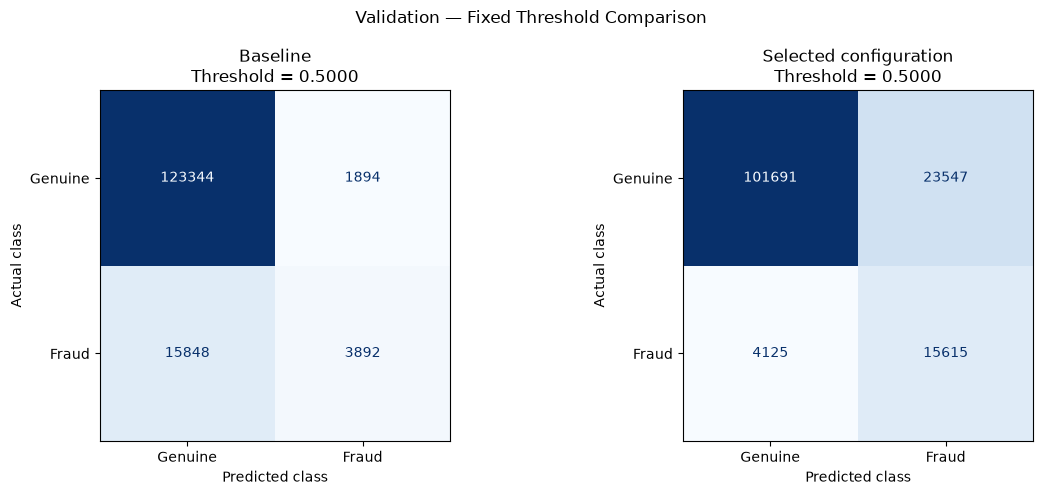

In [17]:
plot_confusion_matrices(
    y_val,
    cases=[
        (name, scores, BASELINE_THRESHOLD)
        for name, scores in comparison_scores.items()
    ],
    title="Validation — Fixed Threshold Comparison"
)

#### `Baseline vs Selected Configuration — Performance Chart`

| Validation metric at `0.5` | Baseline | Selected |
|---|---:|---:|
| Average precision | 0.5282 | 0.5345 |
| Fraud precision | 0.6727 | 0.4035 |
| Fraud recall | 0.1972 | 0.7867 |
| Fraud F1 | 0.3049 | 0.5334 |
| Orders flagged | 3.99% | 26.55% |
| False positives | 1,894 | 22,961 |
| False negatives | 15,848 | 4,210 |

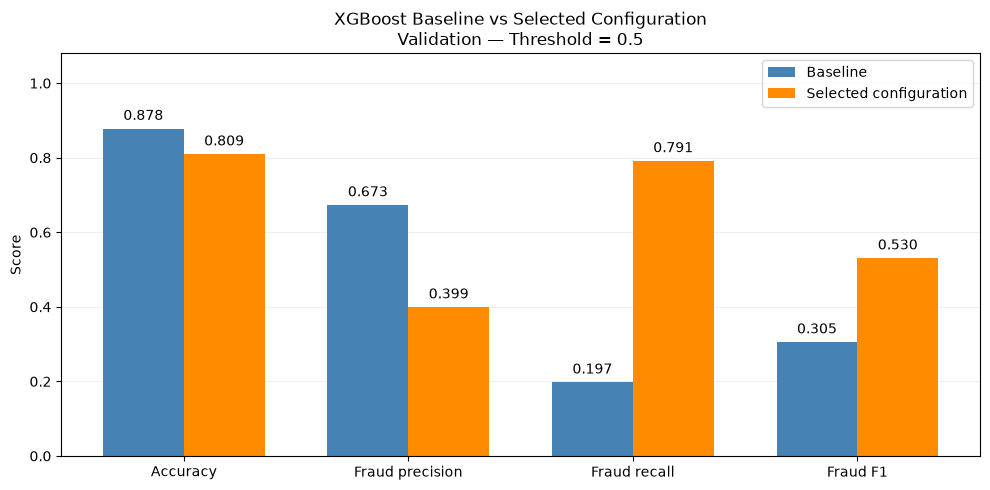

In [18]:
comparison_values = {}

for name, scores in comparison_scores.items():
    predictions = (
        scores >= BASELINE_THRESHOLD
    ).astype(int)

    row = fixed_results.loc[
        fixed_results["Model"] == name
    ].iloc[0]

    comparison_values[name] = [
        accuracy_score(y_val, predictions),
        row["Fraud precision"],
        row["Fraud recall"],
        row["Fraud F1"]
    ]

x = np.arange(len(metric_labels))
width = 0.36

fig, ax = plt.subplots(figsize=(10, 5))

baseline_bars = ax.bar(
    x - width / 2,
    comparison_values["Baseline"],
    width,
    label="Baseline",
    color="steelblue"
)

selected_bars = ax.bar(
    x + width / 2,
    comparison_values["Selected configuration"],
    width,
    label="Selected configuration",
    color="darkorange"
)

ax.bar_label(baseline_bars, fmt="%.3f", padding=4)
ax.bar_label(selected_bars, fmt="%.3f", padding=4)

ax.set_xticks(x)
ax.set_xticklabels(metric_labels)

ax.set(
    title="XGBoost Baseline vs Selected Configuration\n"
          "Validation — Threshold = 0.5",
    ylabel="Score",
    ylim=(0, 1.08)
)

ax.set_yticks(np.arange(0, 1.01, 0.2))
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)
ax.legend()

plt.tight_layout()
plt.show()

#### `Training and Validation Performance`

Compare training and validation AP and unweighted log loss to see how ranking and score quality differ across periods.

In [19]:
from sklearn.metrics import log_loss

xgb_models_to_compare = {
    "Baseline": xgb_baseline,
    "Selected configuration": selected_xgb_model
}

xgb_diagnostic_rows = []
for name, model in xgb_models_to_compare.items():
    train_scores = model.predict_proba(X_train_encoded)[:, 1]
    val_scores = comparison_scores[name]
    train_ap = average_precision_score(y_train, train_scores)
    val_ap = average_precision_score(y_val, val_scores)
    xgb_diagnostic_rows.append({
        "Model": name,
        "Train AP": train_ap,
        "Validation AP": val_ap,
        "AP gap": train_ap - val_ap,
        "Train log loss": log_loss(y_train, train_scores, labels=[0, 1]),
        "Validation log loss": log_loss(y_val, val_scores, labels=[0, 1])
    })

display(pd.DataFrame(xgb_diagnostic_rows).round(4))

,Model,Train AP,Validation AP,AP gap,Train log loss,Validation log loss
0,Baseline,0.4752,0.5282,-0.053,0.2470,0.2973
1,Selected configuration,0.4160,0.5361,-0.120,0.5209,0.4917


#### `Training and Validation Learning Curves`

- Compare **log loss** and XGBoost's **`aucpr`** across boosting rounds.
- Lower log loss and higher `aucpr` indicate better performance on their respective metrics.
- The dashed line marks the round selected by validation `aucpr` (**round 195** in the saved run).

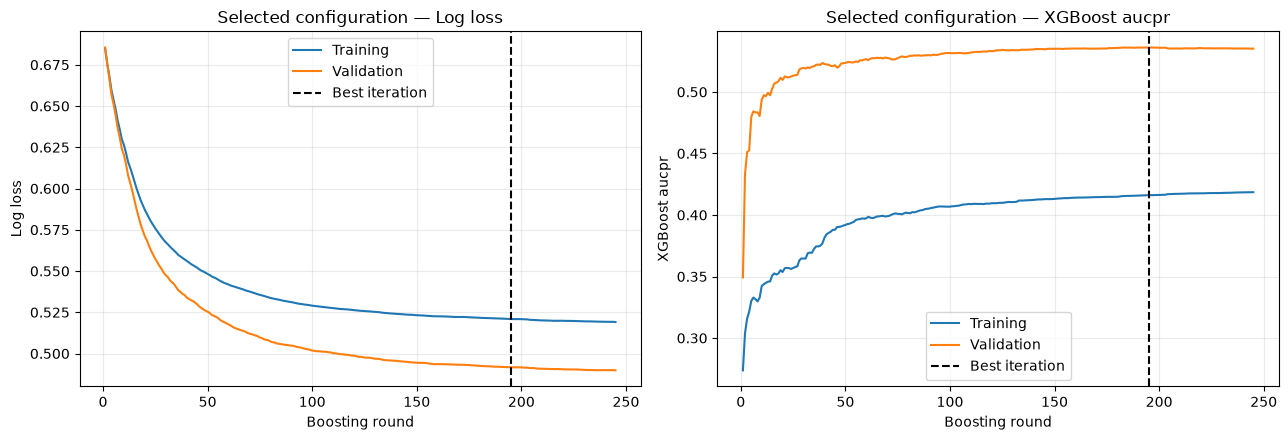

In [20]:
history = selected_xgb_model.evals_result()
selected_config = experiment_configs[selected_xgb_run]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

for ax, metric, ylabel in zip(
    axes,
    ["logloss", "aucpr"],
    ["Log loss", "XGBoost aucpr"]
):
    train_values = history["validation_0"][metric]
    val_values = history["validation_1"][metric]

    rounds = np.arange(1, len(train_values) + 1)

    ax.plot(rounds, train_values, label="Training")
    ax.plot(rounds, val_values, label="Validation")

    if selected_config["early_stopping"]:
        ax.axvline(
            selected_xgb_model.best_iteration + 1,
            color="black",
            linestyle="--",
            label="Best iteration"
        )

    ax.set(
        title=f"Selected configuration — {ylabel}",
        xlabel="Boosting round",
        ylabel=ylabel
    )
    ax.grid(alpha=0.25)
    ax.legend()

plt.tight_layout()
plt.show()

#### `Pipeline Size and In-Memory Loading`

Record the serialized pipeline size and in-memory loading time for the baseline and selected configuration. The size includes preprocessing and the classifier.

In [21]:
import io
from time import perf_counter

import joblib

xgb_resource_rows = []
for name, model in xgb_models_to_compare.items():
    fitted_pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("model", model)
    ])
    buffer = io.BytesIO()
    joblib.dump(fitted_pipeline, buffer, compress=0)
    model_bytes = buffer.getvalue()

    start = perf_counter()
    loaded_pipeline = joblib.load(io.BytesIO(model_bytes))
    load_seconds = perf_counter() - start

    np.testing.assert_allclose(
        loaded_pipeline.predict_proba(X_val.iloc[:100])[:, 1],
        comparison_scores[name][:100],
        rtol=1e-7,
        atol=1e-9
    )
    xgb_resource_rows.append({
        "Model": name,
        "Pipeline size (KiB)": len(model_bytes) / 1024,
        "In-memory load (ms)": load_seconds * 1000
    })

display(pd.DataFrame(xgb_resource_rows).round(4))

,Model,Pipeline size (KiB),In-memory load (ms)
0,Baseline,422.0518,31.5517
1,Selected configuration,248.1553,25.2957


### 5️⃣ Separate Experiment — Tune the Decision Threshold

- Reuse the validation fraud scores from both trained models.
- Search for the cutoff that maximises **fraud F1** for each model. When several thresholds give the same maximum F1, choose the highest one.
- Changing the cutoff changes which orders are flagged. The ranking of scores and AP stay the same for each model on that dataset.

In [22]:
def threshold_search(y_true, scores):
    scores = np.asarray(scores, dtype=float)

    precision, recall, thresholds = precision_recall_curve(
        y_true, scores
    )

    # The final precision/recall pair has no threshold.
    precision = precision[:-1]
    recall = recall[:-1]

    f1 = np.divide(
        2 * precision * recall,
        precision + recall,
        out=np.zeros_like(precision),
        where=(precision + recall) > 0
    )

    # Exact F1 ties: prefer the highest threshold.
    best_positions = np.flatnonzero(f1 == f1.max())
    best_position = best_positions[-1]

    best_threshold = float(thresholds[best_position])

    flagged = len(scores) - np.searchsorted(
        np.sort(scores),
        thresholds,
        side="left"
    )

    curve = pd.DataFrame({
        "Threshold": thresholds,
        "Fraud precision": precision,
        "Fraud recall": recall,
        "Fraud F1": f1,
        "Flagged orders": flagged,
        "Flagged percentage": 100 * flagged / len(scores)
    })

    return best_threshold, curve


tuned_thresholds = {}
threshold_curves = {}
tuned_rows = []

for name, scores in comparison_scores.items():
    threshold, curve = threshold_search(y_val, scores)

    tuned_thresholds[name] = threshold
    threshold_curves[name] = curve

    row = evaluate_fraud_threshold(
        y_val,
        scores,
        threshold,
        run_name=(
            BASELINE_RUN
            if name == "Baseline"
            else selected_xgb_run
        )
    )

    row["Model"] = name
    row["Experiment"] = "Threshold tuned for validation F1"
    tuned_rows.append(row)

    print(f"{name}: threshold = {threshold:.6f}")

tuned_results = pd.DataFrame(tuned_rows)

full_comparison = pd.concat(
    [fixed_results, tuned_results],
    ignore_index=True
)

comparison_columns = [
    "Model",
    "Run",
    "Experiment",
    "Threshold",
    "Average precision",
    "Fraud precision",
    "Fraud recall",
    "Fraud F1",
    "Flagged percentage",
    "False positives",
    "False negatives"
]

display(full_comparison[comparison_columns].round(4))

selected_xgb_threshold = tuned_thresholds[
    "Selected configuration"
]

Baseline: threshold = 0.141980
Selected configuration: threshold = 0.619079


,Model,Run,Experiment,Threshold,Average precision,Fraud precision,Fraud recall,Fraud F1,Flagged percentage,False positives,False negatives
0,Baseline,XGB_baseline,Fixed threshold 0.5,0.5000,0.5282,0.6727,0.1972,0.3049,3.9910,1894,15848
1,Selected configuration,XGB_child_weight5,Fixed threshold 0.5,0.5000,0.5361,0.3987,0.7910,0.5302,27.0124,23547,4125
2,Baseline,XGB_baseline,Threshold tuned for validation F1,0.1420,0.5282,0.4632,0.6928,0.5552,20.3631,15847,6065
3,Selected configuration,XGB_child_weight5,Threshold tuned for validation F1,0.6191,0.5361,0.4708,0.6873,0.5588,19.8761,15249,6173


#### `Validation Confusion Matrices After Threshold Tuning`

| Validation metric | Baseline at `0.1420` | Selected at `0.6059` |
|---|---:|---:|
| Average precision | 0.5282 | 0.5345 |
| Fraud precision | 0.4632 | 0.4674 |
| Fraud recall | 0.6928 | 0.6959 |
| Fraud F1 | 0.5552 | 0.5592 |
| Orders flagged | 20.36% | 20.27% |
| False positives | 15,847 | 15,655 |
| False negatives | 6,065 | 6,003 |

Each model uses its own validation-selected cutoff.

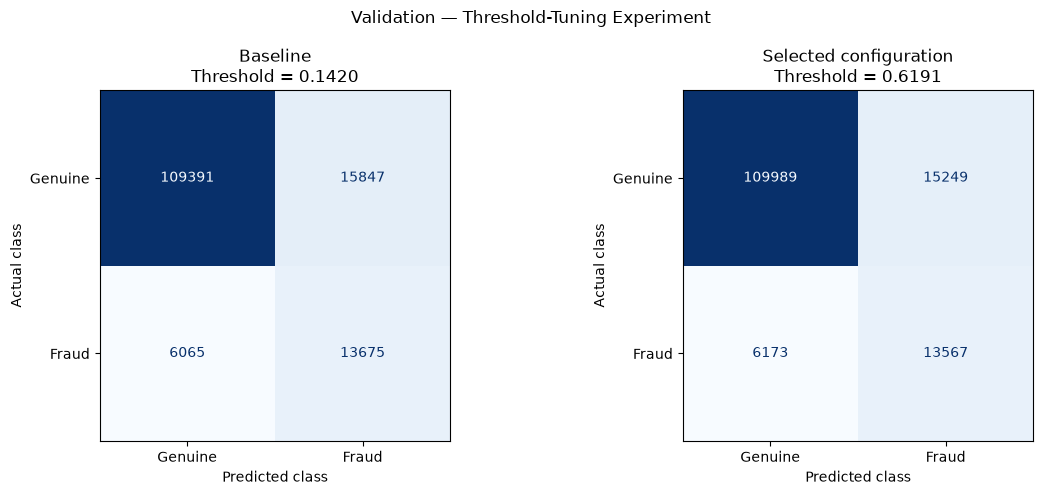

In [23]:
plot_confusion_matrices(
    y_val,
    cases=[
        (
            name,
            scores,
            tuned_thresholds[name]
        )
        for name, scores in comparison_scores.items()
    ],
    title="Validation — Threshold-Tuning Experiment"
)

#### `Precision, Recall and F1 Across Thresholds`

- The dotted line marks the shared cutoff of `0.5`. The dashed line marks the F1-maximising cutoff for each model.
- Read the curves at either line to see how the review decision changes the balance between catching fraud and generating false alerts.

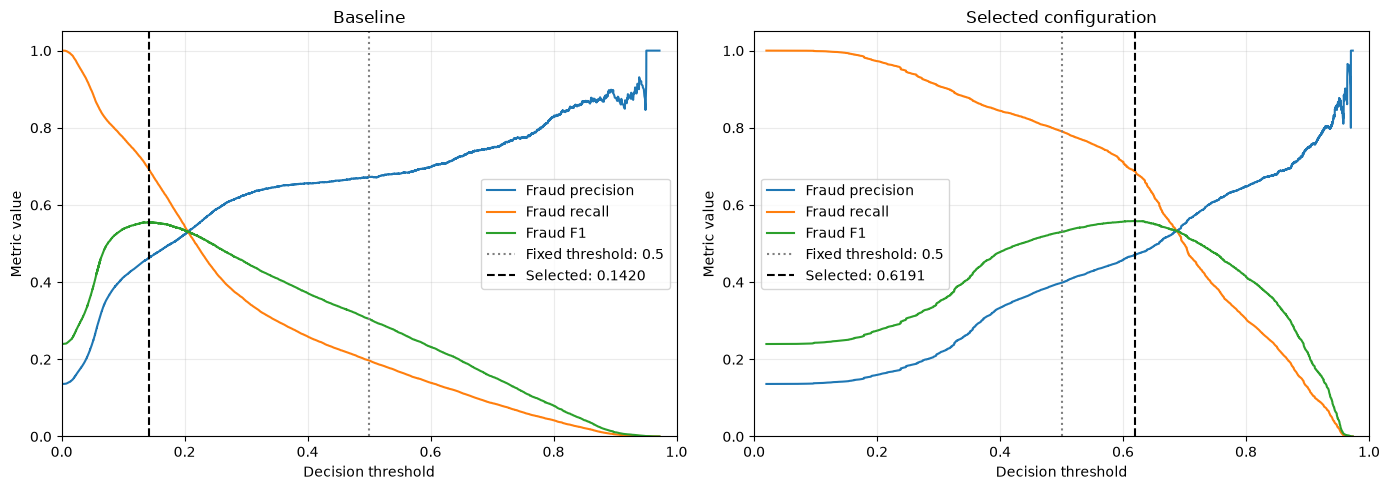

In [24]:
fig, axes = plt.subplots(
    1, 2,
    figsize=(14, 5)
)

for ax, (name, curve) in zip(
    axes, threshold_curves.items()
):
    for metric in [
        "Fraud precision",
        "Fraud recall",
        "Fraud F1"
    ]:
        ax.plot(
            curve["Threshold"],
            curve[metric],
            label=metric
        )

    ax.axvline(
        BASELINE_THRESHOLD,
        color="grey",
        linestyle=":",
        label="Fixed threshold: 0.5"
    )

    ax.axvline(
        tuned_thresholds[name],
        color="black",
        linestyle="--",
        label=f"Selected: {tuned_thresholds[name]:.4f}"
    )

    ax.set(
        title=name,
        xlabel="Decision threshold",
        ylabel="Metric value",
        xlim=(0, 1),
        ylim=(0, 1.05)
    )

    ax.grid(alpha=0.25)
    ax.legend()

plt.tight_layout()
plt.show()

#### `Precision–Recall Comparison`

- Compare the full validation precision–recall curves to assess the models' rankings across cutoffs.
- The dots mark the tuned operating points. The horizontal reference line shows the **13.62%** validation fraud prevalence.

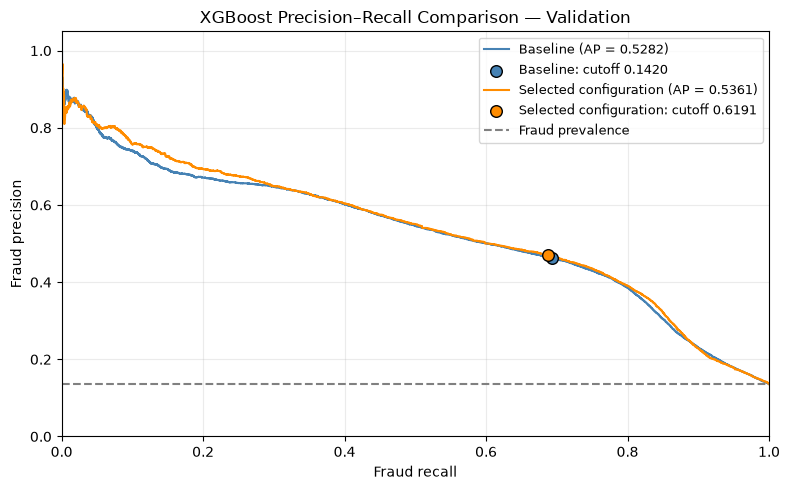

In [25]:
fig, ax = plt.subplots(figsize=(8, 5))

colors = {
    "Baseline": "steelblue",
    "Selected configuration": "darkorange"
}

for name, scores in comparison_scores.items():
    precision, recall, _ = precision_recall_curve(
        y_val, scores
    )

    ap = average_precision_score(y_val, scores)

    ax.step(
        recall,
        precision,
        where="post",
        color=colors[name],
        label=f"{name} (AP = {ap:.4f})"
    )

    predictions = (
        scores >= tuned_thresholds[name]
    ).astype(int)

    ax.scatter(
        recall_score(y_val, predictions, zero_division=0),
        precision_score(y_val, predictions, zero_division=0),
        color=colors[name],
        edgecolor="black",
        s=70,
        zorder=3,
        label=f"{name}: cutoff {tuned_thresholds[name]:.4f}"
    )

ax.axhline(
    y_val.mean(),
    color="grey",
    linestyle="--",
    label="Fraud prevalence"
)

ax.set(
    title="XGBoost Precision–Recall Comparison — Validation",
    xlabel="Fraud recall",
    ylabel="Fraud precision",
    xlim=(0, 1),
    ylim=(0, 1.05)
)

ax.grid(alpha=0.25)
ax.legend(fontsize=9)

plt.tight_layout()
plt.show()

### 6️⃣ Final Evaluation on Unseen Orders

- Use the newest orders from **14 April to 11 May 2023** as the final test set.
- Apply the already fitted preprocessor and score each order with both trained models.
- Evaluate both models at `0.5` and at their validation-selected thresholds. Carry the thresholds forward as selected on validation.

In [26]:
RUN_FINAL_TEST = True # Set to True to run the final test evaluation.

if RUN_FINAL_TEST:
    X_test_encoded = preprocessor.transform(
        X_test
    ).astype(np.float32)

    test_score_dict = {
        "Baseline": xgb_baseline.predict_proba(
            X_test_encoded
        )[:, 1],
        "Selected configuration": selected_xgb_model.predict_proba(
            X_test_encoded
        )[:, 1]
    }

    test_rows = []

    for name, scores in test_score_dict.items():
        run_name = (
            BASELINE_RUN
            if name == "Baseline"
            else selected_xgb_run
        )

        for experiment, threshold in [
            ("Fixed threshold 0.5", BASELINE_THRESHOLD),
            (
                "Validation-selected threshold",
                tuned_thresholds[name]
            )
        ]:
            row = evaluate_fraud_threshold(
                y_test,
                scores,
                threshold,
                run_name
            )

            row["Model"] = name
            row["Experiment"] = experiment
            test_rows.append(row)

    final_test_results = pd.DataFrame(test_rows)

    display(
        final_test_results[comparison_columns].round(4)
    )
else:
    print(
        "Final test evaluation is disabled. "
        "Finish model and threshold selection first."
    )

,Model,Run,Experiment,Threshold,Average precision,Fraud precision,Fraud recall,Fraud F1,Flagged percentage,False positives,False negatives
0,Baseline,XGB_baseline,Fixed threshold 0.5,0.5000,0.4219,0.5310,0.2168,0.3079,5.0534,3416,13968
1,Baseline,XGB_baseline,Validation-selected threshold,0.1420,0.4219,0.3642,0.6664,0.4710,22.6405,20745,5950
2,Selected configuration,XGB_child_weight5,Fixed threshold 0.5,0.5000,0.4275,0.3111,0.7511,0.4400,29.8747,29660,4439
3,Selected configuration,XGB_child_weight5,Validation-selected threshold,0.6191,0.4275,0.3709,0.6599,0.4749,22.0182,19963,6065


#### `Final Test Confusion Matrices`

The matrices show the errors each model made on the newest orders at its validation-selected cutoff.

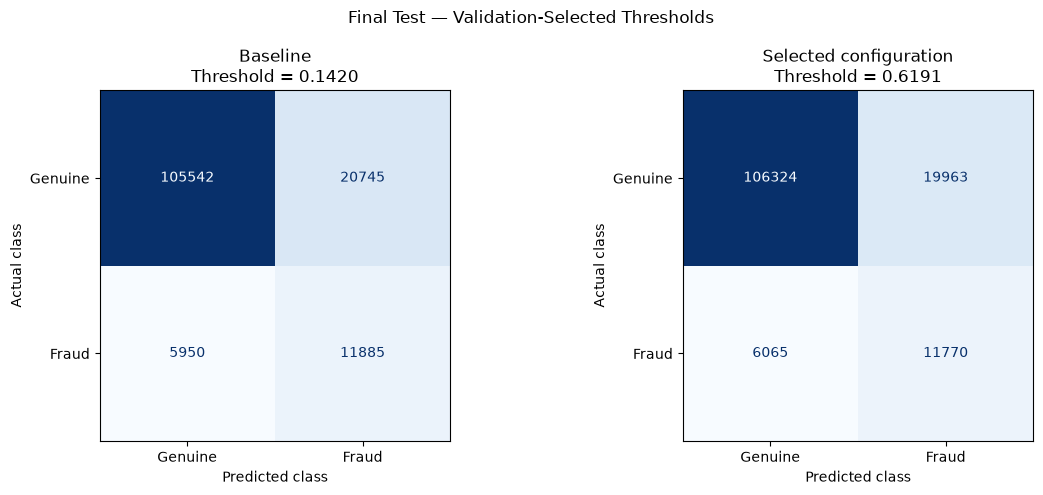

In [27]:
if RUN_FINAL_TEST:
    plot_confusion_matrices(
        y_test,
        cases=[
            (
                name,
                scores,
                tuned_thresholds[name]
            )
            for name, scores in test_score_dict.items()
        ],
        title="Final Test — Validation-Selected Thresholds"
    )

#### `Final XGBoost Summary`

| Test metric | Baseline at `0.1420` | Selected at `0.6059` |
|---|---:|---:|
| Average precision | 0.4219 | 0.4273 |
| Fraud precision | 0.3642 | 0.3684 |
| Fraud recall | 0.6664 | 0.6698 |
| Fraud F1 | 0.4710 | 0.4753 |
| Orders flagged | 22.64% | 22.50% |
| False positives | 20,745 | 20,478 |
| False negatives | 5,950 | 5,890 |

The selected configuration was `XGB_gamma1`. The cell below computes the validation and test summaries from the current run.

In [28]:
if RUN_FINAL_TEST:
    for partition, comparison in [
        ("Validation", full_comparison),
        ("Test", final_test_results)
    ]:
        tuned_results = comparison.loc[
            comparison["Experiment"].isin(["Threshold tuned for validation F1", "Validation-selected threshold"])
        ].set_index("Model")
        baseline = tuned_results.loc["Baseline"]
        selected = tuned_results.loc["Selected configuration"]

        print(f"{partition} — {selected_xgb_run}")
        print(f"AP: {baseline['Average precision']:.4f} → {selected['Average precision']:.4f}")
        print(f"Fraud F1: {baseline['Fraud F1']:.4f} → {selected['Fraud F1']:.4f}")
        print(f"Fraud precision: {baseline['Fraud precision']:.2%} → {selected['Fraud precision']:.2%}")
        print(f"Fraud recall: {baseline['Fraud recall']:.2%} → {selected['Fraud recall']:.2%}")
        print(
            f"Orders flagged: {baseline['Flagged percentage']:.2f}% "
            f"→ {selected['Flagged percentage']:.2f}%"
        )
        print(f"False alerts: {baseline['False positives']:,} → {selected['False positives']:,}")
        print(f"Missed fraud: {baseline['False negatives']:,} → {selected['False negatives']:,}")
        print()

Validation — XGB_child_weight5
AP: 0.5282 → 0.5361
Fraud F1: 0.5552 → 0.5588
Fraud precision: 46.32% → 47.08%
Fraud recall: 69.28% → 68.73%
Orders flagged: 20.36% → 19.88%
False alerts: 15,847 → 15,249
Missed fraud: 6,065 → 6,173

Test — XGB_child_weight5
AP: 0.4219 → 0.4275
Fraud F1: 0.4710 → 0.4749
Fraud precision: 36.42% → 37.09%
Fraud recall: 66.64% → 65.99%
Orders flagged: 22.64% → 22.02%
False alerts: 20,745 → 19,963
Missed fraud: 5,950 → 6,065



## `SP-Buy — Logistic Regression Model Training and Fraud Detection`

### Project Background

Logistic Regression estimates a fraud score for each order. It provides a comparison with XGBoost using the same eight order-level features and chronological split.

- **Prediction target** — `is_fraud`, where `1` indicates fraud and `0` indicates a legitimate order.
- **Model selection** — Rank configurations by validation **average precision (AP)** at the model-selection stage.
- **Threshold selection** — Maximise validation fraud **F1** for each of the two fitted models, then carry those cutoffs forward to the test period.

### 1️⃣ Imports and Data Preparation for Logistic Regression Model

#### `Reuse the Chronological Data Split`

- Use the original eight inputs from `X_train`, `X_val` and `X_test` created in the XGBoost section.
- Fit imputers, scalers, category encoders and classifiers on the training orders. Use validation orders to select settings. Keep the newest orders for final evaluation.

In [29]:
import io
from time import perf_counter
import warnings

import joblib
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import log_loss
from threadpoolctl import threadpool_limits

LR_LOG_FEATURES = ["order_value", "num_items_ordered"]
LR_INTERACTION_FEATURES = [
    "order_value", "num_items_ordered", "days_since_first_order"
]
LR_BASELINE_RUN = "LR_baseline"

display(split_summary[["Partition", "Orders", "Start date", "End date", "Fraud percentage"]])

,Partition,Orders,Start date,End date,Fraud percentage
0,Train,660772,2022-11-12,2023-03-14,10.116500
1,Validation,144978,2023-03-15,2023-04-13,13.615859
2,Test,144122,2023-04-14,2023-05-11,12.374932


### 2️⃣ Build and Evaluate the Baseline Logistic Regression Model

#### `Build Preprocessing and Baseline Pipeline`

- Fill missing numeric values with training medians, then standardise numeric inputs.
- Use `Unknown` for missing categories and one-hot encode them. Ignore unseen categories when scoring later orders.
- Fit `LogisticRegression` with `C=1.0`, `class_weight=None`, the `lbfgs` solver and a maximum of `1000` iterations. Evaluate at the fixed cutoff of **0.5**.

In [30]:
def lr_log1p(values):
    if (values < 0).any():
        raise ValueError("Order value and item count must be nonnegative for log1p.")
    return np.log1p(values)


def lr_order_tenure_products(values):
    order_value, item_count, customer_tenure = values.T
    return np.column_stack([
        order_value * customer_tenure,
        item_count * customer_tenure
    ])


def build_lr_pipeline(C=1.0, class_weight=None, use_log=False, use_interactions=False):
    def numeric_pipeline(apply_log=False):
        steps = [("imputer", SimpleImputer(strategy="median"))]
        if apply_log:
            steps.append(("log1p", FunctionTransformer(lr_log1p)))
        steps.append(("scaler", StandardScaler()))
        return Pipeline(steps)

    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="constant", fill_value="Unknown")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ])

    if use_log:
        remaining_numeric = [
            column for column in NUMERIC_FEATURES if column not in LR_LOG_FEATURES
        ]
        transformers = [
            ("log_numeric", numeric_pipeline(apply_log=True), LR_LOG_FEATURES),
            ("other_numeric", numeric_pipeline(), remaining_numeric)
        ]
    else:
        transformers = [("numeric", numeric_pipeline(), NUMERIC_FEATURES)]

    if use_interactions:
        interaction_pipeline = Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("centre_and_scale", StandardScaler()),
            ("products", FunctionTransformer(lr_order_tenure_products)),
            ("scale_products", StandardScaler())
        ])
        transformers.append(("interactions", interaction_pipeline, LR_INTERACTION_FEATURES))

    transformers.append(("categorical", categorical_pipeline, CATEGORICAL_FEATURES))

    return Pipeline([
        ("preprocessor", ColumnTransformer(transformers)),
        ("model", LogisticRegression(
            C=C, class_weight=class_weight, solver="lbfgs", max_iter=1000
        ))
    ])


lr_baseline = build_lr_pipeline()

#### `Train and Evaluate the Baseline`

- Report AP on training and validation to compare how the model ranks fraud in each period.
- Use the **0.5** cutoff to report fraud precision, recall, F1, flagged orders, false alerts and missed fraud.
- Record training and prediction time for the full pipeline, including preprocessing. These timings describe the current run.

In [31]:
def fit_lr_and_score(model):
    start = perf_counter()
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always", ConvergenceWarning)
        with threadpool_limits(limits=4, user_api="blas"):
            model.fit(X_train, y_train)
    fit_seconds = perf_counter() - start

    converged = not any(issubclass(item.category, ConvergenceWarning) for item in caught)
    for item in caught:
        print(f"{item.category.__name__}: {item.message}")

    start = perf_counter()
    val_scores = model.predict_proba(X_val)[:, 1]
    prediction_seconds = perf_counter() - start
    return val_scores, fit_seconds, prediction_seconds, converged


lr_baseline_fit = fit_lr_and_score(lr_baseline)
lr_baseline_val_scores, lr_fit_seconds, lr_prediction_seconds, lr_baseline_converged = lr_baseline_fit
lr_baseline_train_scores = lr_baseline.predict_proba(X_train)[:, 1]

lr_baseline_results = pd.DataFrame([
    {"Partition": name, **evaluate_fraud_threshold(labels, scores, BASELINE_THRESHOLD, LR_BASELINE_RUN)}
    for name, labels, scores in [
        ("Training", y_train, lr_baseline_train_scores),
        ("Validation", y_val, lr_baseline_val_scores)
    ]
])

display(lr_baseline_results.round(4))
print(f"Fit: {lr_fit_seconds:.3f} s | Validation prediction: {lr_prediction_seconds:.3f} s")
print(f"Converged: {lr_baseline_converged} | Iterations: {lr_baseline.named_steps['model'].n_iter_.max()}")

,Partition,Run,Threshold,Average precision,Fraud precision,Fraud recall,Fraud F1,Flagged orders,Flagged percentage,True negatives,False positives,False negatives,True positives
0,Training,LR_baseline,0.5,0.3079,0.5728,0.0388,0.0727,4532,0.6859,591989,1936,64251,2596
1,Validation,LR_baseline,0.5,0.4730,0.6815,0.0442,0.0831,1281,0.8836,124830,408,18867,873


Fit: 5.597 s | Validation prediction: 0.368 s
Converged: True | Iterations: 38


#### `Baseline Confusion Matrix`

Count correctly classified orders, false alerts and missed fraud on validation at the fixed cutoff of **0.5**.

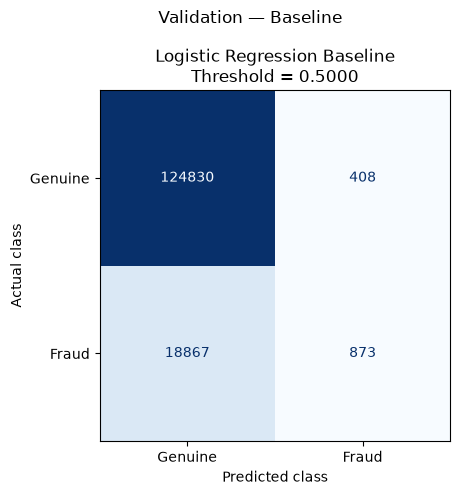

In [32]:
plot_confusion_matrices(
    y_val,
    cases=[("Logistic Regression Baseline", lr_baseline_val_scores, BASELINE_THRESHOLD)],
    title="Validation — Baseline"
)

#### `Baseline Performance Chart`

Compare accuracy with fraud precision, recall and F1 at **0.5**. Validation fraud prevalence was **13.62%**.

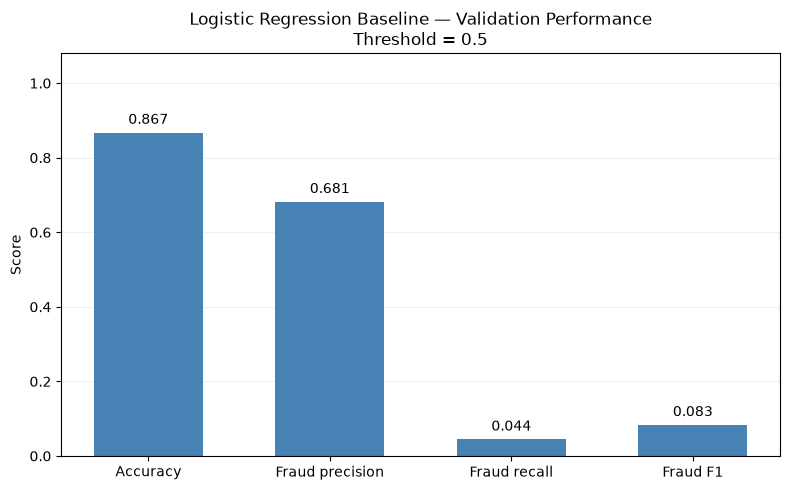

In [33]:
lr_baseline_predictions = (
    lr_baseline_val_scores >= BASELINE_THRESHOLD
).astype(int)

lr_baseline_row = lr_baseline_results.loc[lr_baseline_results["Partition"].eq("Validation")].iloc[0]

lr_metric_labels = [
    "Accuracy", "Fraud precision", "Fraud recall", "Fraud F1"
]

lr_baseline_values = [
    accuracy_score(y_val, lr_baseline_predictions),
    lr_baseline_row["Fraud precision"],
    lr_baseline_row["Fraud recall"],
    lr_baseline_row["Fraud F1"]
]

fig, ax = plt.subplots(figsize=(8, 5))

bars = ax.bar(
    lr_metric_labels,
    lr_baseline_values,
    color="steelblue",
    width=0.6
)

ax.bar_label(bars, fmt="%.3f", padding=4)

ax.set(
    title="Logistic Regression Baseline — Validation Performance\nThreshold = 0.5",
    ylabel="Score",
    ylim=(0, 1.08)
)

ax.set_yticks(np.arange(0, 1.01, 0.2))
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

#### `Baseline Score Distributions`

Compare the distribution of validation fraud scores within each actual class. The dashed line marks the **0.5** cutoff.

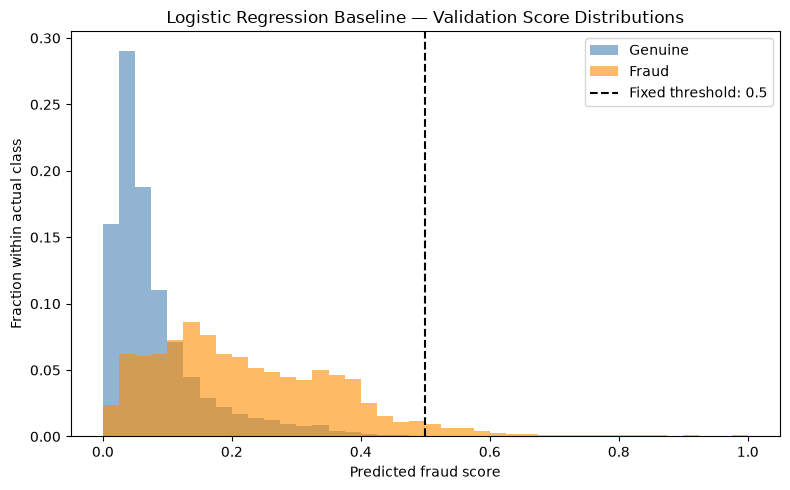

In [34]:
fig, ax = plt.subplots(figsize=(8, 5))
lr_actual_labels = np.asarray(y_val)

for label, name, color in [(0, "Genuine", "steelblue"), (1, "Fraud", "darkorange")]:
    scores = lr_baseline_val_scores[lr_actual_labels == label]
    ax.hist(
        scores,
        bins=np.linspace(0, 1, 41),
        weights=np.full(len(scores), 1 / len(scores)),
        alpha=0.6,
        color=color,
        label=name
    )

ax.axvline(BASELINE_THRESHOLD, color="black", linestyle="--", label="Fixed threshold: 0.5")
ax.set(
    xlabel="Predicted fraud score",
    ylabel="Fraction within actual class",
    title="Logistic Regression Baseline — Validation Score Distributions"
)
ax.legend()
plt.tight_layout()
plt.show()

#### `Baseline Logistic Regression Summary`

- **Fraud ranking.** Validation AP was **0.4730**, compared with fraud prevalence of **13.62%**.
- **Review workload at 0.5.** The baseline flagged **1,281 of 144,978** validation orders. It detected **873** fraud cases, raised **408** false alerts and missed **18,867** fraud cases.
- **Next experiment.** The low recall at 0.5 motivates testing whether class weighting, regularisation and feature changes improve the scores before tuning the decision threshold.

### 3️⃣ Improve the Logistic Regression Model

#### Test Targeted Improvements

| Change | Candidates | Reason to test |
|---|---|---|
| Class weighting | `None` or `"balanced"` | Giving fraud more weight during training may improve recall. Check the accompanying change in false alerts. |
| Regularisation | `C = 0.01, 0.1, 1, 10` | Smaller `C` strengthens regularisation. Compare which setting ranks validation fraud best. |
| Numeric transforms | Original inputs or `log1p` on `order_value` and `num_items_ordered` | Compressing large values may help the linear model fit skewed order inputs. |
| Feature interactions | Off or two products involving days since first order | The relationship between order value or basket size and fraud may vary with customer tenure. |
| Decision threshold | `0.5` during configuration comparison, then tune on validation | Adjust the trade-off between missed fraud and orders sent for review. |

The two interactions are **order value × customer tenure** and **item count × customer tenure**. Here, tenure is measured by `days_since_first_order`. The interaction branch imputes and standardises the original operands before multiplying them. The original main effects remain in the pipeline. The two products are tested together so the experiment measures their combined effect.

Fit all **32 configurations** across regularisation, class weighting, numeric transforms and interactions. Reuse the fitted baseline for its matching configuration. Use the same **0.5** cutoff throughout this stage so the model comparison and cutoff experiment can be read separately.

In [35]:
lr_experiment_rows = []
lr_feature_settings = list(product(
    [False, True],
    [False, True],
    [None, "balanced"],
    [0.01, 0.1, 1.0, 10.0]
))

lr_best_key = None
selected_lr_model = None

for number, (use_log, use_interactions, class_weight, C) in enumerate(lr_feature_settings, start=1):
    transform_name = "log1p" if use_log else "original"
    interaction_name = "on" if use_interactions else "off"
    weight_name = "none" if class_weight is None else class_weight
    run_name = f"LR_{transform_name}_int-{interaction_name}_weight-{weight_name}_C-{C:g}"

    if (use_log, use_interactions, class_weight, C) == (False, False, None, 1.0):
        run_name = LR_BASELINE_RUN
        model = lr_baseline
        fit_result = lr_baseline_fit
    else:
        model = build_lr_pipeline(C, class_weight, use_log, use_interactions)
        fit_result = fit_lr_and_score(model)

    scores, fit_seconds, prediction_seconds, converged = fit_result
    row = evaluate_fraud_threshold(y_val, scores, BASELINE_THRESHOLD, run_name)
    row.update({
        "Numeric transform": transform_name,
        "Interactions": interaction_name,
        "Class weight": weight_name,
        "C": C,
        "Converged": converged,
        "Iterations": int(model.named_steps["model"].n_iter_.max()),
        "Fit seconds": fit_seconds,
        "Prediction seconds": prediction_seconds
    })
    lr_experiment_rows.append(row)

    selection_key = (row["Average precision"], row["Fraud F1"])
    if converged and (lr_best_key is None or selection_key > lr_best_key):
        lr_best_key = selection_key
        selected_lr_model = model
        selected_lr_run = run_name
        selected_lr_val_scores = scores

    print(
        f"[{number:02d}/{len(lr_feature_settings)}] {run_name} "
        f"| AP={row['Average precision']:.4f} | F1@0.5={row['Fraud F1']:.4f}"
    )

[01/32] LR_original_int-off_weight-none_C-0.01 | AP=0.4732 | F1@0.5=0.0764
[02/32] LR_original_int-off_weight-none_C-0.1 | AP=0.4729 | F1@0.5=0.0830
[03/32] LR_baseline | AP=0.4730 | F1@0.5=0.0831
[04/32] LR_original_int-off_weight-none_C-10 | AP=0.4730 | F1@0.5=0.0831
[05/32] LR_original_int-off_weight-balanced_C-0.01 | AP=0.4704 | F1@0.5=0.4709
[06/32] LR_original_int-off_weight-balanced_C-0.1 | AP=0.4703 | F1@0.5=0.4710
[07/32] LR_original_int-off_weight-balanced_C-1 | AP=0.4702 | F1@0.5=0.4709
[08/32] LR_original_int-off_weight-balanced_C-10 | AP=0.4702 | F1@0.5=0.4709
[09/32] LR_original_int-on_weight-none_C-0.01 | AP=0.4759 | F1@0.5=0.0807
[10/32] LR_original_int-on_weight-none_C-0.1 | AP=0.4756 | F1@0.5=0.0840
[11/32] LR_original_int-on_weight-none_C-1 | AP=0.4758 | F1@0.5=0.0852
[12/32] LR_original_int-on_weight-none_C-10 | AP=0.4759 | F1@0.5=0.0853
[13/32] LR_original_int-on_weight-balanced_C-0.01 | AP=0.4751 | F1@0.5=0.4711
[14/32] LR_original_int-on_weight-balanced_C-0.1 | A

#### `Select the Configuration by Validation Average Precision`

- Among converged runs, select the highest validation AP. Break exact AP ties by fraud F1 at **0.5**, then by experiment order.
- Compare the selected configuration with runs that change **one setting at a time**. Each row varies one setting and keeps the other three at the selected values.
- The best F1 or recall at **0.5** can belong to a different configuration because the cutoff is applied to the scores each model produces.

In [36]:
lr_grid_metrics = [
    "Average precision", "Fraud precision", "Fraud recall", "Fraud F1",
    "Flagged percentage", "False positives", "False negatives"
]
lr_setting_columns = ["Numeric transform", "Interactions", "Class weight", "C"]

lr_ranked_results = (
    pd.DataFrame(lr_experiment_rows)
    .sort_values(
        ["Converged", "Average precision", "Fraud F1"],
        ascending=False,
        kind="stable"
    )
    .reset_index(drop=True)
)
display(lr_ranked_results[
    ["Run", *lr_setting_columns, *lr_grid_metrics, "Converged", "Iterations",
     "Fit seconds", "Prediction seconds"]
].round(4))

if selected_lr_model is None:
    raise RuntimeError("No Logistic Regression configuration converged.")

lr_selected_settings = lr_ranked_results.loc[lr_ranked_results["Run"].eq(selected_lr_run)].iloc[0]
print("Selected configuration:", selected_lr_run)

lr_matched_comparisons = []
for setting in lr_setting_columns:
    matched = lr_ranked_results.loc[lr_ranked_results["Converged"]]
    for fixed_setting in lr_setting_columns:
        if fixed_setting != setting:
            matched = matched.loc[matched[fixed_setting].eq(lr_selected_settings[fixed_setting])]

    matched = matched.assign(
        **{"Setting varied": setting,
           "AP change vs selected": matched["Average precision"] - lr_selected_settings["Average precision"]}
    )
    lr_matched_comparisons.append(matched)

display(pd.concat(lr_matched_comparisons, ignore_index=True)[
    ["Setting varied", *lr_setting_columns, "Average precision", "AP change vs selected",
     "Fraud recall", "False positives", "Flagged percentage"]
].round(4))

,Run,Numeric transform,Interactions,Class weight,C,Average precision,Fraud precision,Fraud recall,Fraud F1,Flagged percentage,False positives,False negatives,Converged,Iterations,Fit seconds,Prediction seconds
0,LR_log1p_int-on_weight-balanced_C-0.01,log1p,on,balanced,0.01,0.4951,0.3268,0.7827,0.4611,32.6070,31823,4290,True,58,5.3386,0.3193
1,LR_log1p_int-on_weight-balanced_C-0.1,log1p,on,balanced,0.10,0.4949,0.3269,0.7827,0.4611,32.6063,31821,4289,True,81,6.6974,0.3232
2,LR_log1p_int-on_weight-balanced_C-10,log1p,on,balanced,10.00,0.4948,0.3273,0.7826,0.4615,32.5594,31755,4291,True,72,6.1528,0.3227
3,LR_log1p_int-on_weight-balanced_C-1,log1p,on,balanced,1.00,0.4948,0.3271,0.7826,0.4614,32.5718,31774,4292,True,71,6.0561,0.3214
4,LR_log1p_int-on_weight-none_C-0.01,log1p,on,none,0.01,0.4920,0.7843,0.0558,0.1042,0.9691,303,18638,True,36,4.6496,0.3176
5,LR_log1p_int-on_weight-none_C-10,log1p,on,none,10.00,0.4918,0.7735,0.0585,0.1087,1.0291,338,18586,True,36,4.4738,0.3276
6,LR_log1p_int-on_weight-none_C-1,log1p,on,none,1.00,0.4918,0.7735,0.0585,0.1087,1.0291,338,18586,True,36,4.5818,0.3222
7,LR_log1p_int-on_weight-none_C-0.1,log1p,on,none,0.10,0.4914,0.7726,0.0580,0.1079,1.0222,337,18595,True,38,4.6013,0.3121
8,LR_log1p_int-off_weight-balanced_C-0.01,log1p,off,balanced,0.01,0.4899,0.3265,0.7833,0.4609,32.6670,31897,4277,True,55,5.0445,0.2910
9,LR_log1p_int-off_weight-balanced_C-1,log1p,off,balanced,1.00,0.4894,0.3270,0.7828,0.4613,32.6008,31811,4287,True,68,5.3866,0.2881


Selected configuration: LR_log1p_int-on_weight-balanced_C-0.01


,Setting varied,Numeric transform,Interactions,Class weight,C,Average precision,AP change vs selected,Fraud recall,False positives,Flagged percentage
0,Numeric transform,log1p,on,balanced,0.01,0.4951,0.0000,0.7827,31823,32.6070
1,Numeric transform,original,on,balanced,0.01,0.4751,-0.0200,0.7929,31059,32.2194
2,Interactions,log1p,on,balanced,0.01,0.4951,0.0000,0.7827,31823,32.6070
3,Interactions,log1p,off,balanced,0.01,0.4899,-0.0053,0.7833,31897,32.6670
4,Class weight,log1p,on,balanced,0.01,0.4951,0.0000,0.7827,31823,32.6070
5,Class weight,log1p,on,none,0.01,0.4920,-0.0032,0.0558,303,0.9691
6,C,log1p,on,balanced,0.01,0.4951,0.0000,0.7827,31823,32.6070
7,C,log1p,on,balanced,0.10,0.4949,-0.0002,0.7827,31821,32.6063
8,C,log1p,on,balanced,10.00,0.4948,-0.0003,0.7826,31755,32.5594
9,C,log1p,on,balanced,1.00,0.4948,-0.0004,0.7826,31774,32.5718


- **Selected configuration.** `C=0.01`, balanced class weights, `log1p` on order value and item count, and both tenure interactions gave the highest validation AP of **0.4951**, up from **0.4730** for the baseline.
- **Matched comparisons.** With the other selected settings fixed, using the original numeric inputs lowered AP to **0.4751**. Removing both interactions lowered it to **0.4899**. The numeric transform had the largest effect among the matched comparisons for the selected configuration.

### 4️⃣ Compare Baseline and Selected Logistic Regression Models

#### `Compare Both Models at a Fixed Cutoff of 0.5`

Evaluate both models on the same validation orders. Compare average precision, fraud precision, recall, F1 and review workload.

In [37]:
lr_models_to_compare = {
    "Baseline": (LR_BASELINE_RUN, lr_baseline, lr_baseline_val_scores),
    "Selected configuration": (selected_lr_run, selected_lr_model, selected_lr_val_scores)
}
lr_comparison_columns = [
    "Model", "Run", "Experiment", "Threshold", *lr_grid_metrics, "Flagged orders"
]


def compare_lr_cutoffs(y_true, model_scores, cutoffs):
    rows = []
    for name, scores in model_scores.items():
        run_name = lr_models_to_compare[name][0]
        for experiment, threshold in cutoffs[name]:
            rows.append({
                "Model": name,
                "Experiment": experiment,
                **evaluate_fraud_threshold(y_true, scores, threshold, run_name)
            })
    return pd.DataFrame(rows)[lr_comparison_columns]


lr_validation_scores = {
    name: model_and_scores[2] for name, model_and_scores in lr_models_to_compare.items()
}
lr_fixed_cutoffs = {
    name: [("Fixed threshold 0.5", BASELINE_THRESHOLD)] for name in lr_models_to_compare
}
lr_fixed_results = compare_lr_cutoffs(y_val, lr_validation_scores, lr_fixed_cutoffs)
display(lr_fixed_results.round(4))

,Model,Run,Experiment,Threshold,Average precision,Fraud precision,Fraud recall,Fraud F1,Flagged percentage,False positives,False negatives,Flagged orders
0,Baseline,LR_baseline,Fixed threshold 0.5,0.5,0.4730,0.6815,0.0442,0.0831,0.8836,408,18867,1281
1,Selected configuration,LR_log1p_int-on_weight-balanced_C-0.01,Fixed threshold 0.5,0.5,0.4951,0.3268,0.7827,0.4611,32.6070,31823,4290,47273


#### Confusion Matrices at a Fixed Cutoff of 0.5

Compare false alerts and missed fraud for both configurations at the same cutoff.

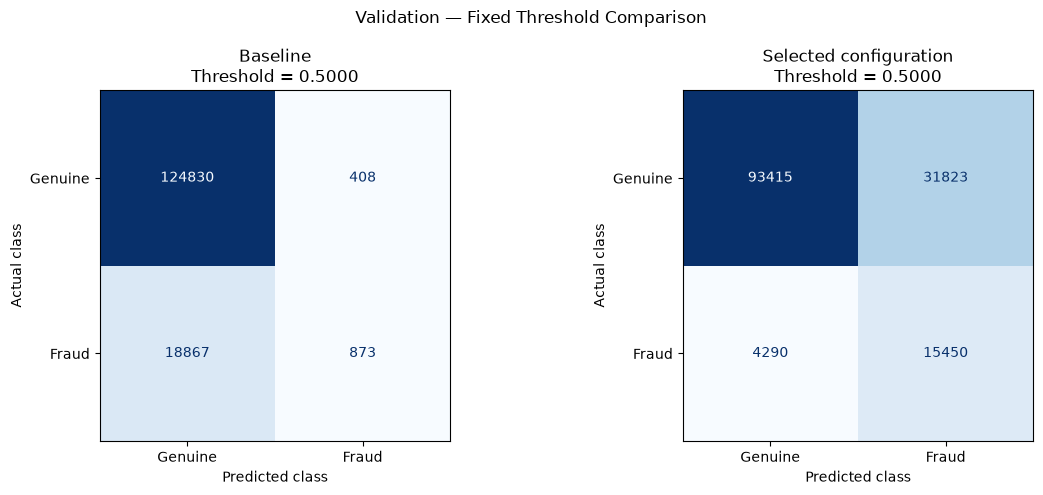

In [38]:
plot_confusion_matrices(
    y_val,
    cases=[(name, scores, BASELINE_THRESHOLD) for name, scores in lr_validation_scores.items()],
    title="Validation — Fixed Threshold Comparison"
)

#### `Baseline vs Selected Configuration — Performance Chart`

Compare accuracy, fraud precision, recall and F1 at **0.5**.

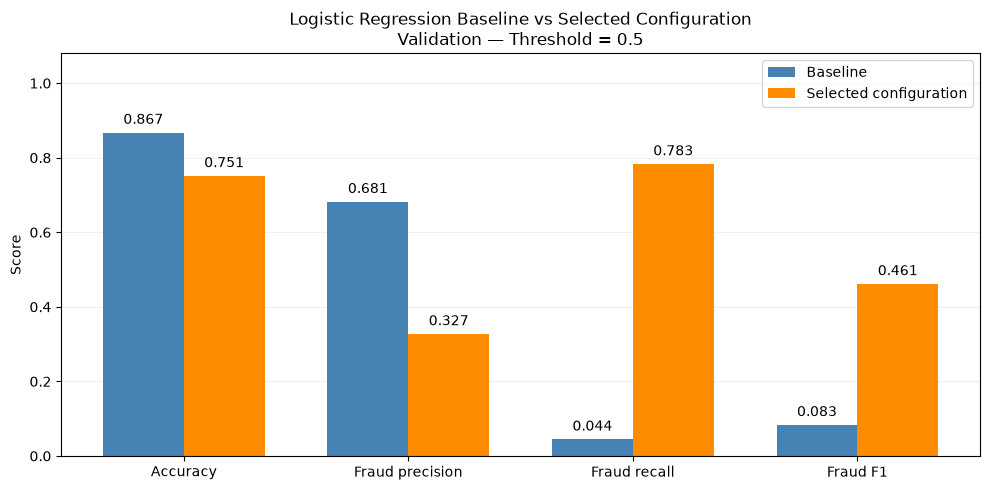

In [39]:
lr_comparison_values = {}

for name, scores in lr_validation_scores.items():
    predictions = (
        scores >= BASELINE_THRESHOLD
    ).astype(int)

    row = lr_fixed_results.loc[
        lr_fixed_results["Model"] == name
    ].iloc[0]

    lr_comparison_values[name] = [
        accuracy_score(y_val, predictions),
        row["Fraud precision"],
        row["Fraud recall"],
        row["Fraud F1"]
    ]

x = np.arange(len(lr_metric_labels))
width = 0.36

fig, ax = plt.subplots(figsize=(10, 5))

baseline_bars = ax.bar(
    x - width / 2,
    lr_comparison_values["Baseline"],
    width,
    label="Baseline",
    color="steelblue"
)

selected_bars = ax.bar(
    x + width / 2,
    lr_comparison_values["Selected configuration"],
    width,
    label="Selected configuration",
    color="darkorange"
)

ax.bar_label(baseline_bars, fmt="%.3f", padding=4)
ax.bar_label(selected_bars, fmt="%.3f", padding=4)

ax.set_xticks(x)
ax.set_xticklabels(lr_metric_labels)

ax.set(
    title="Logistic Regression Baseline vs Selected Configuration\n"
          "Validation — Threshold = 0.5",
    ylabel="Score",
    ylim=(0, 1.08)
)

ax.set_yticks(np.arange(0, 1.01, 0.2))
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)
ax.legend()

plt.tight_layout()
plt.show()

#### `Training and Validation Performance`

Compare training and validation AP and unweighted log loss to see how ranking and score quality differ across periods.

In [40]:
lr_diagnostic_rows = []
for name, (_, model, val_scores) in lr_models_to_compare.items():
    train_scores = (
        lr_baseline_train_scores if model is lr_baseline
        else model.predict_proba(X_train)[:, 1]
    )
    train_ap = average_precision_score(y_train, train_scores)
    val_ap = average_precision_score(y_val, val_scores)
    lr_diagnostic_rows.append({
        "Model": name,
        "Train AP": train_ap,
        "Validation AP": val_ap,
        "AP gap": train_ap - val_ap,
        "Train log loss": log_loss(y_train, train_scores, labels=[0, 1]),
        "Validation log loss": log_loss(y_val, val_scores, labels=[0, 1])
    })

display(pd.DataFrame(lr_diagnostic_rows).round(4))

,Model,Train AP,Validation AP,AP gap,Train log loss,Validation log loss
0,Baseline,0.3079,0.4730,-0.1652,0.2807,0.3165
1,Selected configuration,0.3139,0.4951,-0.1812,0.5691,0.5299


#### Pipeline Size and In-Memory Loading

Record the serialized pipeline size and in-memory loading time for the baseline and selected configuration. The size includes preprocessing and the classifier.

In [41]:
lr_resource_rows = []
for name, (_, model, val_scores) in lr_models_to_compare.items():
    buffer = io.BytesIO()
    joblib.dump(model, buffer, compress=0)
    model_bytes = buffer.getvalue()

    start = perf_counter()
    loaded_model = joblib.load(io.BytesIO(model_bytes))
    load_seconds = perf_counter() - start

    np.testing.assert_allclose(
        loaded_model.predict_proba(X_val.iloc[:100])[:, 1], val_scores[:100],
        rtol=1e-10, atol=1e-12
    )
    lr_resource_rows.append({
        "Model": name,
        "Pipeline size (KiB)": len(model_bytes) / 1024,
        "In-memory load (ms)": load_seconds * 1000
    })

display(pd.DataFrame(lr_resource_rows).round(4))

,Model,Pipeline size (KiB),In-memory load (ms)
0,Baseline,5.5566,6.0844
1,Selected configuration,7.8223,9.8151


### 5️⃣ Separate Experiment — Tune the Decision Threshold

- Search every distinct validation score for the cutoff that maximises **fraud F1**. Choose the highest cutoff when F1 is tied, as in the XGBoost section.
- Tune the baseline and selected model independently using the same rule. Compare both at **0.5** and at their own tuned cutoffs.
- Compare false alerts, missed fraud and the percentage of orders flagged. AP stays fixed for a given model on the same orders because tuning only changes the cutoff.

In [42]:
lr_tuned_thresholds = {}
lr_threshold_curves = {}

for name, scores in lr_validation_scores.items():
    cutoff, curve = threshold_search(y_val, scores)
    lr_tuned_thresholds[name] = cutoff
    lr_threshold_curves[name] = curve
    print(f"{name}: threshold = {cutoff:.6f}")

lr_all_cutoffs = {
    name: [*lr_fixed_cutoffs[name], ("Validation-selected threshold", lr_tuned_thresholds[name])]
    for name in lr_models_to_compare
}
lr_validation_comparison = compare_lr_cutoffs(y_val, lr_validation_scores, lr_all_cutoffs)
display(lr_validation_comparison.round(4))

Baseline: threshold = 0.146886
Selected configuration: threshold = 0.631272


,Model,Run,Experiment,Threshold,Average precision,Fraud precision,Fraud recall,Fraud F1,Flagged percentage,False positives,False negatives,Flagged orders
0,Baseline,LR_baseline,Fixed threshold 0.5,0.5000,0.4730,0.6815,0.0442,0.0831,0.8836,408,18867,1281
1,Baseline,LR_baseline,Validation-selected threshold,0.1469,0.4730,0.4201,0.6435,0.5083,20.8563,17535,7038,30237
2,Selected configuration,LR_log1p_int-on_weight-balanced_C-0.01,Fixed threshold 0.5,0.5000,0.4951,0.3268,0.7827,0.4611,32.6070,31823,4290,47273
3,Selected configuration,LR_log1p_int-on_weight-balanced_C-0.01,Validation-selected threshold,0.6313,0.4951,0.4440,0.5981,0.5097,18.3428,14786,7933,26593


#### `Validation Confusion Matrices After Threshold Tuning`

Each model uses its own validation-selected cutoff. Compare false alerts and missed fraud at those cutoffs.

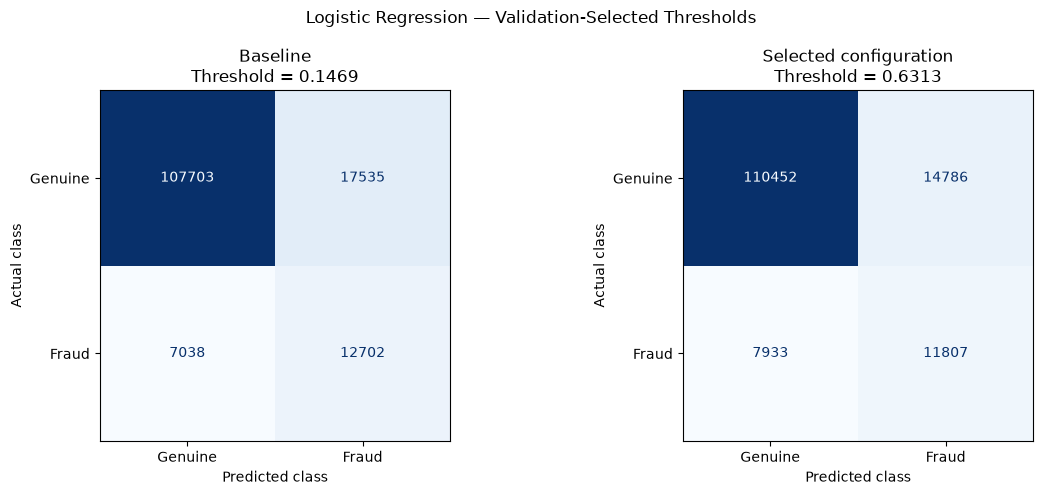

In [43]:
plot_confusion_matrices(
    y_val,
    [(name, scores, lr_tuned_thresholds[name]) for name, scores in lr_validation_scores.items()],
    title="Logistic Regression — Validation-Selected Thresholds"
)

#### `Precision, Recall and F1 Across Thresholds`

- The dotted line marks the shared cutoff of `0.5`. The dashed line marks the F1-maximising cutoff for each model.
- Read the curves at either line to see how the review decision changes the balance between catching fraud and generating false alerts.

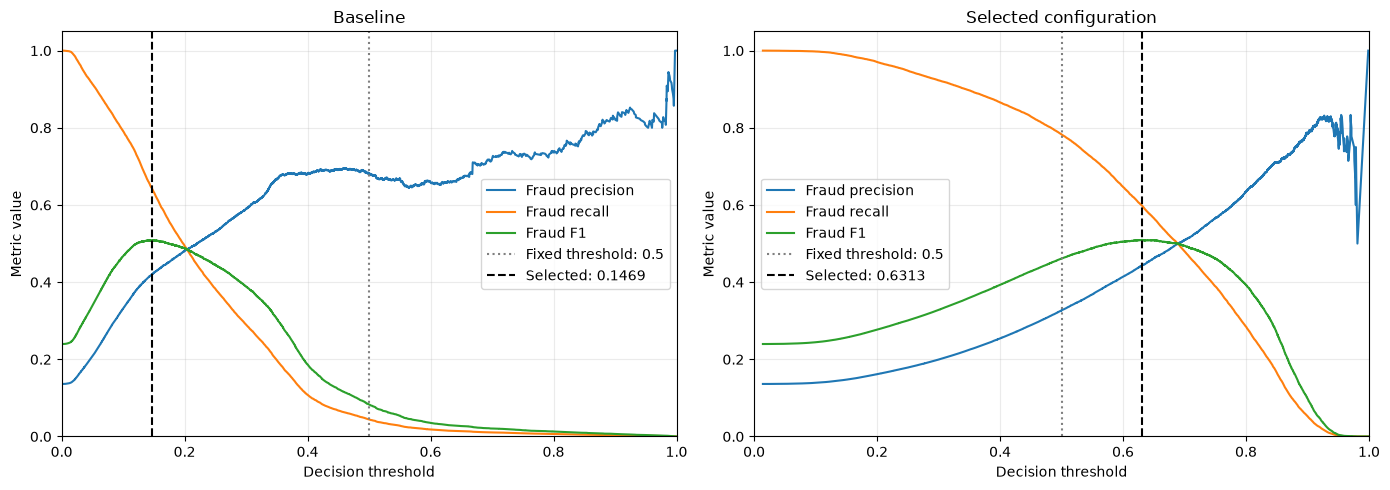

In [44]:
fig, axes = plt.subplots(
    1, 2,
    figsize=(14, 5)
)

for ax, (name, curve) in zip(
    axes, lr_threshold_curves.items()
):
    for metric in [
        "Fraud precision",
        "Fraud recall",
        "Fraud F1"
    ]:
        ax.plot(
            curve["Threshold"],
            curve[metric],
            label=metric
        )

    ax.axvline(
        BASELINE_THRESHOLD,
        color="grey",
        linestyle=":",
        label="Fixed threshold: 0.5"
    )

    ax.axvline(
        lr_tuned_thresholds[name],
        color="black",
        linestyle="--",
        label=f"Selected: {lr_tuned_thresholds[name]:.4f}"
    )

    ax.set(
        title=name,
        xlabel="Decision threshold",
        ylabel="Metric value",
        xlim=(0, 1),
        ylim=(0, 1.05)
    )

    ax.grid(alpha=0.25)
    ax.legend()

plt.tight_layout()
plt.show()

#### `Precision–Recall Comparison`

Compare how both models rank validation fraud across cutoffs. The dots mark the validation-selected cutoffs and the dashed horizontal line marks validation fraud prevalence.

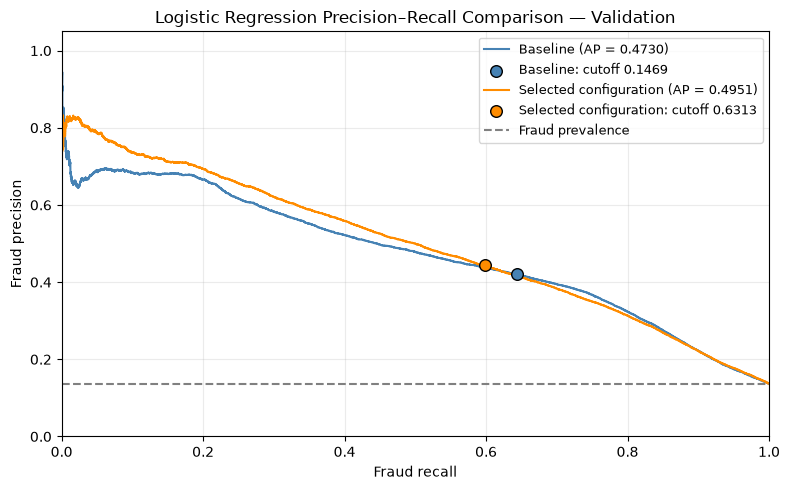

In [45]:
fig, ax = plt.subplots(figsize=(8, 5))

colors = {
    "Baseline": "steelblue",
    "Selected configuration": "darkorange"
}

for name, scores in lr_validation_scores.items():
    precision, recall, _ = precision_recall_curve(
        y_val, scores
    )

    ap = average_precision_score(y_val, scores)

    ax.step(
        recall,
        precision,
        where="post",
        color=colors[name],
        label=f"{name} (AP = {ap:.4f})"
    )

    predictions = (
        scores >= lr_tuned_thresholds[name]
    ).astype(int)

    ax.scatter(
        recall_score(y_val, predictions, zero_division=0),
        precision_score(y_val, predictions, zero_division=0),
        color=colors[name],
        edgecolor="black",
        s=70,
        zorder=3,
        label=f"{name}: cutoff {lr_tuned_thresholds[name]:.4f}"
    )

ax.axhline(
    y_val.mean(),
    color="grey",
    linestyle="--",
    label="Fraud prevalence"
)

ax.set(
    title="Logistic Regression Precision–Recall Comparison — Validation",
    xlabel="Fraud recall",
    ylabel="Fraud precision",
    xlim=(0, 1),
    ylim=(0, 1.05)
)

ax.grid(alpha=0.25)
ax.legend(fontsize=9)

plt.tight_layout()
plt.show()

### 6️⃣ Final Evaluation on Unseen Orders

- Use the newest orders from the shared chronological split to evaluate both fitted Logistic Regression pipelines.
- Apply the fixed **0.5** cutoff and each model's validation-selected cutoff to the test scores. Keep the fitted models and cutoffs fixed.
- Compare baseline and selected models at their tuned cutoffs to assess changes in ranking, F1, false alerts, missed fraud and review workload.

In [46]:
lr_test_scores = {
    name: model.predict_proba(X_test)[:, 1]
    for name, (_, model, _) in lr_models_to_compare.items()
}
lr_final_test_results = compare_lr_cutoffs(y_test, lr_test_scores, lr_all_cutoffs)
display(lr_final_test_results.round(4))

,Model,Run,Experiment,Threshold,Average precision,Fraud precision,Fraud recall,Fraud F1,Flagged percentage,False positives,False negatives,Flagged orders
0,Baseline,LR_baseline,Fixed threshold 0.5,0.5000,0.3798,0.6319,0.0469,0.0873,0.9180,487,16999,1323
1,Baseline,LR_baseline,Validation-selected threshold,0.1469,0.3798,0.3179,0.6428,0.4254,25.0232,24600,6371,36064
2,Selected configuration,LR_log1p_int-on_weight-balanced_C-0.01,Fixed threshold 0.5,0.5000,0.4082,0.2456,0.7668,0.3721,38.6312,42000,4159,55676
3,Selected configuration,LR_log1p_int-on_weight-balanced_C-0.01,Validation-selected threshold,0.6313,0.4082,0.3286,0.6096,0.4271,22.9535,22209,6963,33081


#### `Final Test Confusion Matrices`

The matrices show the errors each model made on the newest orders at its validation-selected cutoff.

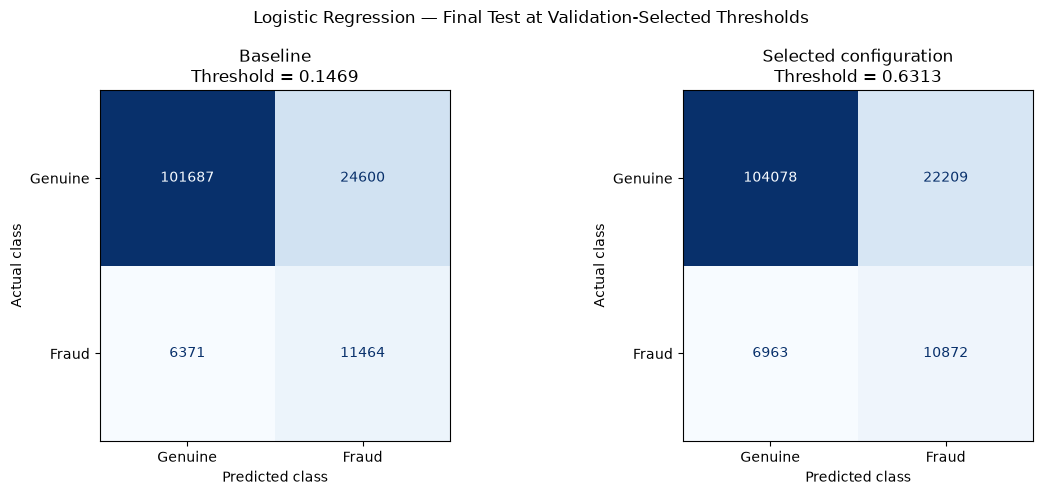

In [47]:
plot_confusion_matrices(
    y_test,
    [(name, scores, lr_tuned_thresholds[name]) for name, scores in lr_test_scores.items()],
    title="Logistic Regression — Final Test at Validation-Selected Thresholds"
)

#### `Final Logistic Regression Summary`

| Test metric | Baseline at `0.1469` | Selected at `0.6313` |
|---|---:|---:|
| Average precision | 0.3798 | **0.4082** |
| Fraud precision | 31.79% | **32.86%** |
| Fraud recall | **64.28%** | 60.96% |
| Fraud F1 | 0.4254 | **0.4271** |
| Orders flagged | 25.02% | 22.95% |
| False positives | 24,600 | 22,209 |
| False negatives | 6,371 | 6,963 |

- **Fraud ranking.** Test AP rose by **0.0284**. Fraud F1 increased by **0.0017** at the validation-selected cutoffs.
- **Review trade-off.** The selected model raised **2,391 fewer false alerts** and missed **592 more fraud cases** on the test orders. It reduced the share of orders sent for review by **2.07 percentage points**.

The cell below computes the validation and test summaries from the current run.

In [48]:
for partition, comparison in [
    ("Validation", lr_validation_comparison),
    ("Test", lr_final_test_results)
]:
    tuned_results = comparison.loc[
        comparison["Experiment"].eq("Validation-selected threshold")
    ].set_index("Model")
    baseline = tuned_results.loc["Baseline"]
    selected = tuned_results.loc["Selected configuration"]

    print(f"{partition} — {selected_lr_run}")
    print(f"AP: {baseline['Average precision']:.4f} → {selected['Average precision']:.4f}")
    print(f"Fraud F1: {baseline['Fraud F1']:.4f} → {selected['Fraud F1']:.4f}")
    print(f"Fraud precision: {baseline['Fraud precision']:.2%} → {selected['Fraud precision']:.2%}")
    print(f"Fraud recall: {baseline['Fraud recall']:.2%} → {selected['Fraud recall']:.2%}")
    print(
        f"Orders flagged: {baseline['Flagged percentage']:.2f}% "
        f"→ {selected['Flagged percentage']:.2f}%"
    )
    print(f"False alerts: {baseline['False positives']:,} → {selected['False positives']:,}")
    print(f"Missed fraud: {baseline['False negatives']:,} → {selected['False negatives']:,}")
    print()

Validation — LR_log1p_int-on_weight-balanced_C-0.01
AP: 0.4730 → 0.4951
Fraud F1: 0.5083 → 0.5097
Fraud precision: 42.01% → 44.40%
Fraud recall: 64.35% → 59.81%
Orders flagged: 20.86% → 18.34%
False alerts: 17,535 → 14,786
Missed fraud: 7,038 → 7,933

Test — LR_log1p_int-on_weight-balanced_C-0.01
AP: 0.3798 → 0.4082
Fraud F1: 0.4254 → 0.4271
Fraud precision: 31.79% → 32.86%
Fraud recall: 64.28% → 60.96%
Orders flagged: 25.02% → 22.95%
False alerts: 24,600 → 22,209
Missed fraud: 6,371 → 6,963



### 7️⃣ Compare the Two Final Best Performing Models

In [49]:
# Pair each fitted model with its validation scores and tuned cutoff.
final_candidates = {
    "XGBoost": {
        "run": selected_xgb_run,
        "model": Pipeline([
            ("preprocessor", preprocessor),
            ("model", selected_xgb_model),
        ]),
        "val_scores": selected_xgb_scores,
        "threshold": selected_xgb_threshold,
    },
    "Logistic Regression": {
        "run": selected_lr_run,
        "model": selected_lr_model,
        "val_scores": selected_lr_val_scores,
        "threshold": lr_tuned_thresholds["Selected configuration"],
    },
}

# Compare both models on the same validation orders.
validation_comparison = pd.DataFrame([
    {
        "Model": name,
        **evaluate_fraud_threshold(
            y_val,
            candidate["val_scores"],
            candidate["threshold"],
            candidate["run"],
        ),
    }
    for name, candidate in final_candidates.items()
]).sort_values(
    ["Fraud F1", "Fraud recall"],
    ascending=[False, False],
    ignore_index=True,
)

result_columns = [
    "Model", "Run", "Threshold", "Average precision",
    "Fraud precision", "Fraud recall", "Fraud F1",
    "Flagged percentage", "False positives", "False negatives",
]

print("Validation comparison — ranked by fraud F1, then recall")
display(validation_comparison[result_columns].round(4))

# Keep the winning fitted model and its original cutoff.
best_model_name = validation_comparison.loc[0, "Model"]
winner = final_candidates[best_model_name]
best_model = winner["model"]
best_threshold = winner["threshold"]

print(f"Selected model: {best_model_name} ({winner['run']})")
print(f"Decision cutoff: {best_threshold:.6f}")

# Evaluate the winner on the shared chronological test set.
best_test_scores = best_model.predict_proba(X_test)[:, 1]
best_test_result = pd.DataFrame([{
    "Model": best_model_name,
    **evaluate_fraud_threshold(
        y_test, best_test_scores, best_threshold, winner["run"]
    ),
}])

print("Final test performance")
display(best_test_result[result_columns].round(4))

Validation comparison — ranked by fraud F1, then recall


,Model,Run,Threshold,Average precision,Fraud precision,Fraud recall,Fraud F1,Flagged percentage,False positives,False negatives
0,XGBoost,XGB_child_weight5,0.6191,0.5361,0.4708,0.6873,0.5588,19.8761,15249,6173
1,Logistic Regression,LR_log1p_int-on_weight-balanced_C-0.01,0.6313,0.4951,0.4440,0.5981,0.5097,18.3428,14786,7933


Selected model: XGBoost (XGB_child_weight5)
Decision cutoff: 0.619079
Final test performance


,Model,Run,Threshold,Average precision,Fraud precision,Fraud recall,Fraud F1,Flagged percentage,False positives,False negatives
0,XGBoost,XGB_child_weight5,0.6191,0.4275,0.3709,0.6599,0.4749,22.0182,19963,6065


#### `Plot Best Final Model Confusion Matrix`

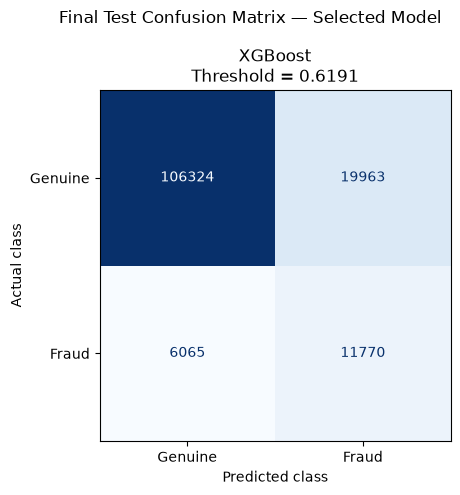

In [50]:
plot_confusion_matrices(
    y_test,
    cases=[(best_model_name, best_test_scores, best_threshold)],
    title="Final Test Confusion Matrix — Selected Model",
)

### 8️⃣ Final Model Selection — XGBoost at a Threshold of `0.6191`

Tuned XGBoost model (`XGB_child_weight5`) was selected because it achieved the highest validation fraud F1 and recall among the two finalists. Fraud F1 was the primary selection metric because it balances how many flagged orders are actually fraudulent (precision) with how many fraud cases the model catches (recall).

| Selected model | Validation fraud F1 | Validation fraud recall | Test fraud F1 | Test fraud recall |
|---|---:|---:|---:|---:|
| **XGBoost (`0.6191`)** | **0.5588** | **68.73%** | **0.4749** | **65.99%** |
| Logistic Regression (`0.6313`) | 0.5097 | 59.81% | 0.4271 | 60.96% |

The `0.6191` threshold maximised XGBoost’s fraud F1 on the validation set. We applied that same threshold to the chronological test set, where the model caught **65.99% of fraudulent orders** while flagging **22.02% of all orders** for review.

Compared with using `0.5` on the same XGBoost model, the tuned threshold raised test fraud F1 from **0.4400 to 0.4749** and reduced the share of orders flagged from **29.87% to 22.02%**. Recall fell from **75.11% to 65.99%**. This trade-off supports `0.6191` as the final cutoff when the priority is balancing fraud detection with the number of orders sent for review.